# Confidence-Score Based Sensor Fusion

Development notebook for building and validating an **innovation-based confidence-weighted sensor fusion** algorithm for the antenna pointing system.

The pipeline follows these steps:
1. **Data Generation** — Simulate realistic single-axis rotation driven by integrated Brownian motion (Brownian Motion → Acceleration → Velocity → Angle), with a sudden jolt in the middle of the run
2. **Sensor Modelling** — Add two sensors (Encoder & AHRS) with distinct noise profiles
3. **Confidence Scoring** — Compute per-sensor confidence using dynamic variance and drift penalty
4. **Sensor Fusion** — Direct confidence-weighted angle fusion in the 1D domain
5. **EKF Baseline** — Fuse the same sensor data with an Extended Kalman Filter for comparison
6. **Final Preview** — Evaluate and visualize both fusion methods against the ground truth

---
## 1. Data Generation & Environment

We generate a realistic single-axis rotation trajectory. The antenna starts at 0° and moves
within the range **[-90°, +90°]**.

The driving stochastic process evolves as a damped **Brownian motion** (Wiener process) representing
stochastic torque disturbance / angular jerk. The kinematics follow a 3-stage integration chain:
1. The **angular acceleration** is obtained from the **integral of the Brownian motion**.
2. The **angular velocity** is obtained from the **integral of the acceleration**.
3. The **true rotation angle** is obtained by **integrating that velocity**.

Reflective boundaries at ±90° keep the trajectory within physical limits by reversing velocity and acceleration.

$$j_{BM}(t + \Delta t) = \alpha \cdot j_{BM}(t) + \sigma_{BM} \sqrt{\Delta t} \cdot \mathcal{N}(0,1)$$

$$a(t + \Delta t) = a(t) + j_{BM}(t) \cdot \Delta t$$

$$\omega(t + \Delta t) = \omega(t) + a(t) \cdot \Delta t$$

$$\theta(t + \Delta t) = \theta(t) + \omega(t) \cdot \Delta t$$

where $\alpha = 0.998$ is a damping coefficient that stabilizes the driving Brownian motion process.

### Sudden jolt
At $t = 15$ s (the middle of the run) the true angle steps by $8^\circ$ within a single sample, which models a mechanical shock,
backlash, or a slip in the drive train. The step is applied toward the centre of the range, so it never
pushes the antenna past a wall. Because the antenna itself moves, **both sensors see the jolt** (it is not a
sensor fault). It sits between the two encoder drift events, so its effect on every metric below
can be read on its own.

$$\theta(t_j) \leftarrow \theta(t_j) - \mathrm{sign}\big(\theta(t_j - \Delta t)\big) \cdot A_{jolt}, \qquad t_j = 15\ \mathrm{s},\ A_{jolt} = 8^\circ$$

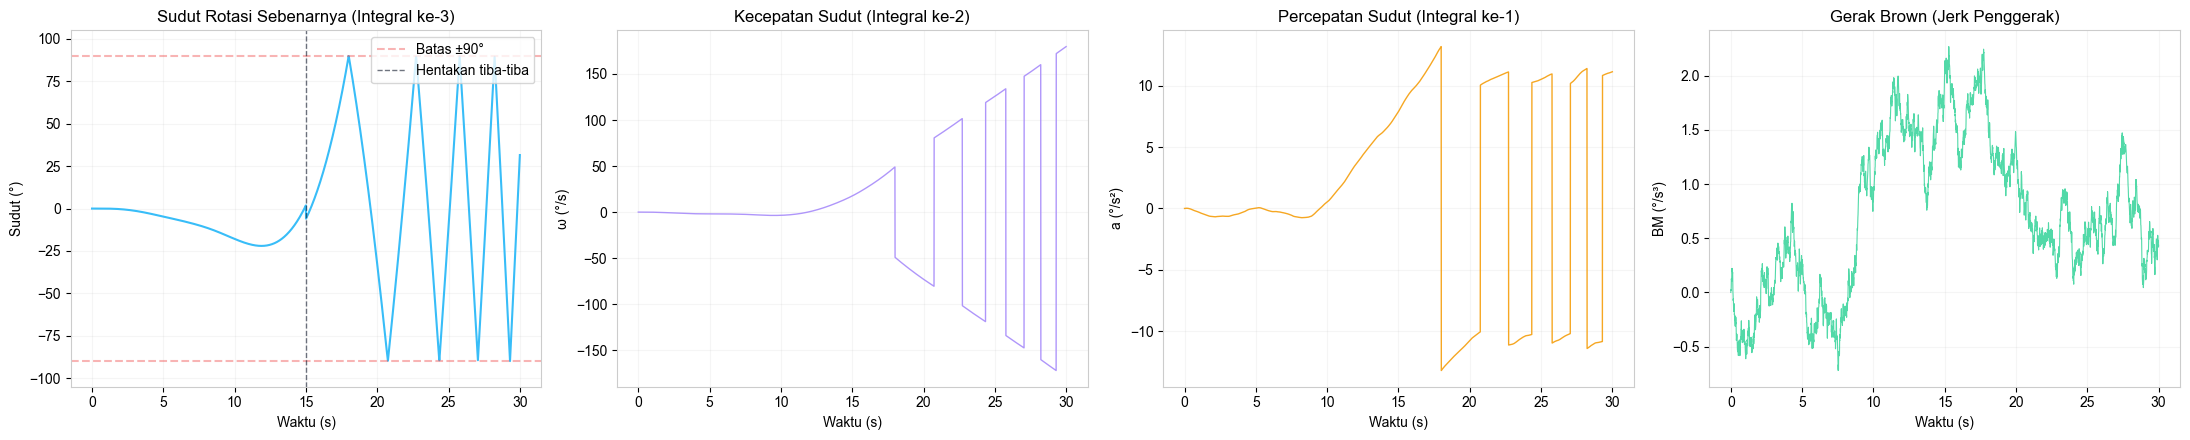

Duration: 30.0s  |  Samples: 3000  |  dt: 0.01s
Angle range: [-89.9°, 89.9°]
Sudden jolt: -7.8° step at t = 15.0s
Velocity range: [-172.0°/s, 179.7°/s]  |  std: 77.3°/s
Acceleration range: [-13.2°/s², 13.2°/s²]  |  std: 7.8°/s²
BM driving range: [-0.7, 2.3]  |  std: 0.7


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rcParams

# ── Plotting style ────────────────────────────────────────────────────────
plt.style.use('default')
rcParams['font.family'] = 'Arial'
rcParams['mathtext.fontset'] = 'custom'   # $math$ labels in Arial too
rcParams['mathtext.rm'] = 'Arial'
rcParams['mathtext.it'] = 'Arial:italic'
rcParams['mathtext.bf'] = 'Arial:bold'
rcParams['axes.edgecolor'] = '#cccccc'
rcParams['axes.facecolor'] = '#ffffff'
rcParams['figure.facecolor'] = '#ffffff'

# ── Simulation parameters ─────────────────────────────────────────────────
np.random.seed(42)
dt       = 0.01       # Time step (s)
T        = 30.0       # Total duration (s)
N        = int(T / dt)
t        = np.linspace(0, T, N)

sigma_bm = 0.5        # Brownian motion volatility (°/s³ per √s)
alpha    = 0.998      # Damping coefficient for Brownian motion
ANGLE_LIMIT = 90.0    # ±90° boundaries

JOLT_IDX = 1500       # Sudden jolt at t = 15 s: mid-run, between the two encoder drift events
JOLT_AMP = 8.0        # Jolt size (°): a one-sample step in the true angle

# ── Generate trajectory via integrated Brownian motion ───────────────────
bm         = np.zeros(N)   # Brownian motion (driving stochastic jerk / disturbance rate, °/s³)
acc        = np.zeros(N)   # Angular acceleration (°/s²) — 1st integral of BM
omega      = np.zeros(N)   # Angular velocity (°/s) — 2nd integral (integral of acceleration)
theta_true = np.zeros(N)   # True angle (°) — 3rd integral (integral of velocity)

for i in range(1, N):
    # 1. Brownian motion step with damping
    bm[i] = alpha * bm[i-1] + sigma_bm * np.sqrt(dt) * np.random.randn()

    # 2. First integral: Brownian motion -> Angular acceleration
    acc[i] = acc[i-1] + bm[i] * dt

    # 3. Second integral: Angular acceleration -> Angular velocity
    omega[i] = omega[i-1] + acc[i] * dt

    # 4. Third integral: Angular velocity -> True rotation angle
    theta_true[i] = theta_true[i-1] + omega[i] * dt

    # 5. Sudden jolt: one-sample step in the true angle, pushed toward the centre of the range
    if i == JOLT_IDX:
        theta_true[i] += -JOLT_AMP if theta_true[i-1] > 0 else JOLT_AMP

    # Reflective boundaries at ±90°
    if theta_true[i] > ANGLE_LIMIT:
        theta_true[i] = 2 * ANGLE_LIMIT - theta_true[i]
        omega[i] = -abs(omega[i])
        acc[i] = -abs(acc[i])
    elif theta_true[i] < -ANGLE_LIMIT:
        theta_true[i] = -2 * ANGLE_LIMIT - theta_true[i]
        omega[i] = abs(omega[i])
        acc[i] = abs(acc[i])

# ── Plots ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 4, figsize=(22, 4.5))

axes[0].plot(t, theta_true, color='#38bdf8', linewidth=1.5)
axes[0].axhline(y= ANGLE_LIMIT, color='#ef4444', ls='--', alpha=0.4, label='Batas ±90°')
axes[0].axhline(y=-ANGLE_LIMIT, color='#ef4444', ls='--', alpha=0.4)
axes[0].set_title('Sudut Rotasi Sebenarnya (Integral ke-3)', fontsize=12)
axes[0].set_xlabel('Waktu (s)'); axes[0].set_ylabel('Sudut (°)')
axes[0].set_ylim(-105, 105)
axes[0].axvline(t[JOLT_IDX], color='#0f172a', ls='--', lw=1.0, alpha=0.6, label='Hentakan tiba-tiba')
axes[0].legend(loc='upper right'); axes[0].grid(alpha=0.12)

axes[1].plot(t, omega, color='#a78bfa', linewidth=1.0, alpha=0.9)
axes[1].set_title('Kecepatan Sudut (Integral ke-2)', fontsize=12)
axes[1].set_xlabel('Waktu (s)'); axes[1].set_ylabel('ω (°/s)')
axes[1].grid(alpha=0.12)

axes[2].plot(t, acc, color='#f59e0b', linewidth=1.0, alpha=0.9)
axes[2].set_title('Percepatan Sudut (Integral ke-1)', fontsize=12)
axes[2].set_xlabel('Waktu (s)'); axes[2].set_ylabel('a (°/s²)')
axes[2].grid(alpha=0.12)

axes[3].plot(t, bm, color='#34d399', linewidth=0.8, alpha=0.85)
axes[3].set_title('Gerak Brown (Jerk Penggerak)', fontsize=12)
axes[3].set_xlabel('Waktu (s)'); axes[3].set_ylabel('BM (°/s³)')
axes[3].grid(alpha=0.12)

plt.tight_layout()
plt.show()

print(f'Duration: {T}s  |  Samples: {N}  |  dt: {dt}s')
print(f'Angle range: [{theta_true.min():.1f}°, {theta_true.max():.1f}°]')
print(f'Sudden jolt: {theta_true[JOLT_IDX] - theta_true[JOLT_IDX-1]:+.1f}° step at t = {t[JOLT_IDX]:.1f}s')
print(f'Velocity range: [{omega.min():.1f}°/s, {omega.max():.1f}°/s]  |  std: {omega.std():.1f}°/s')
print(f'Acceleration range: [{acc.min():.1f}°/s², {acc.max():.1f}°/s²]  |  std: {acc.std():.1f}°/s²')
print(f'BM driving range: [{bm.min():.1f}, {bm.max():.1f}]  |  std: {bm.std():.1f}')


---
## 2. Sensor Readings & Noise

We model **two independent sensors** measuring the same rotation:

| Sensor  | Characteristic | Noise Model |
|---------|---------------|-------------|
| **Encoder** | High precision, but susceptible to occasional drift | $\theta_{enc} = \theta_{true} + \mathcal{N}(0, \sigma_{enc}) + \text{drift}(t)$ |
| **AHRS**    | Noisier overall, but drift-free | $\theta_{ahrs} = \theta_{true} + \mathcal{N}(0, \sigma_{ahrs})$ |

The encoder has a **lower base noise** ($\sigma_{enc} = 1.5°$) but experiences **two drift events** during
the simulation. The AHRS has a **higher base noise** ($\sigma_{ahrs} = 5.0°$) but remains consistently unbiased.

The sudden jolt from §1 is part of the true motion, so both sensors follow it (dashed line in the plots).

This asymmetry is what makes the confidence-weighted fusion valuable — the algorithm should
automatically trust each sensor more during its reliable periods.

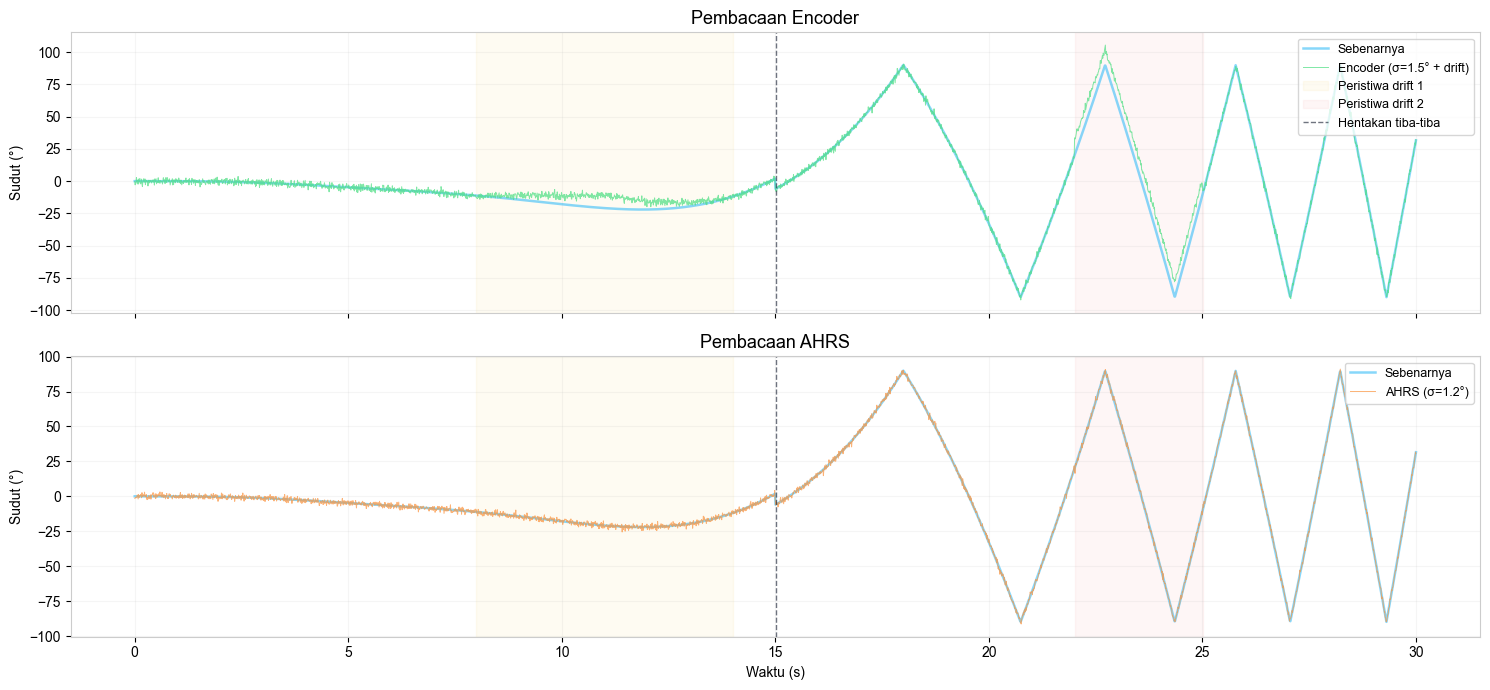

In [2]:
# ── Sensor noise parameters ───────────────────────────────────────────────
sigma_enc  = 1.5    # Encoder base noise σ (°)
sigma_ahrs = 1.2    # AHRS base noise σ (°)

# ── Encoder drift profile ─────────────────────────────────────────────────
# Simulates two real-world failure modes:
#   1) Gradual drift (mechanical slip)   → samples 800–1400
#   2) Sudden offset (electrical glitch) → samples 2200–2500
drift_enc = np.zeros(N)
# Event 1: gradual drift up to 10° and back
ramp_up   = np.linspace(0, 10, 300)
ramp_down = np.linspace(10, 0, 300)
drift_enc[800:1100]  = ramp_up
drift_enc[1100:1400] = ramp_down
# Event 2: sudden offset of 12°
drift_enc[2200:2500] = 12.0

# ── Event markers (used by every time-series plot below) ──────────────────
def mark_events(ax, label=False):
    """Shade the two encoder drift events and mark the sudden jolt."""
    ax.axvspan(t[800],  t[1400], alpha=0.06, color='#fbbf24', label='Peristiwa drift 1' if label else None)
    ax.axvspan(t[2200], t[2500], alpha=0.06, color='#f87171', label='Peristiwa drift 2' if label else None)
    ax.axvline(t[JOLT_IDX], color='#0f172a', ls='--', lw=1.0, alpha=0.6, label='Hentakan tiba-tiba' if label else None)

# ── Generate noisy sensor readings ────────────────────────────────────────
noise_enc  = np.random.normal(0, sigma_enc,  N)
noise_ahrs = np.random.normal(0, sigma_ahrs, N)

theta_enc  = theta_true + noise_enc + drift_enc
theta_ahrs = theta_true + noise_ahrs

# ── Plots ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True)

axes[0].plot(t, theta_true, color='#38bdf8', lw=1.8, label='Sebenarnya', alpha=0.6)
axes[0].plot(t, theta_enc,  color='#4ade80', lw=0.7, alpha=0.7,
             label=f'Encoder (σ={sigma_enc}° + drift)')
mark_events(axes[0], label=True)
axes[0].set_title('Pembacaan Encoder', fontsize=13)
axes[0].set_ylabel('Sudut (°)')
axes[0].legend(loc='upper right', fontsize=9); axes[0].grid(alpha=0.12)

axes[1].plot(t, theta_true, color='#38bdf8', lw=1.8, label='Sebenarnya', alpha=0.6)
axes[1].plot(t, theta_ahrs, color='#fb923c', lw=0.7, alpha=0.7,
             label=f'AHRS (σ={sigma_ahrs}°)')
mark_events(axes[1])
axes[1].set_title('Pembacaan AHRS', fontsize=13)
axes[1].set_xlabel('Waktu (s)'); axes[1].set_ylabel('Sudut (°)')
axes[1].legend(loc='upper right', fontsize=9); axes[1].grid(alpha=0.12)

plt.tight_layout()
plt.show()

---
## 3. Confidence Scoring (Innovation-Based Inverse Variance)

Rather than penalizing both sensors symmetrically using a cross-sensor mean, we employ an
**Innovation-Based Inverse Variance** weighting scheme with targeted drift penalty.

### 1. Prior Baseline Noise
Each sensor has an established baseline noise variance from its specification:
$$\sigma_{prior, enc} = 1.5^\circ, \quad \sigma_{prior, ahrs} = 1.2^\circ$$

### 2. Detrended Dynamic Variance
A causal sliding window measures real-time noise variance $\sigma_i^2$ over window $W = 50$ samples.

**Critical detail:** The variance is computed on *detrended* data within each window. A linear
trend is fitted and subtracted before computing variance. This isolates the sensor noise
characteristics from the physical trajectory motion, which would otherwise dominate the
variance estimate (raw trajectory variance ≈ 12°² vs actual noise variance ≈ 2°²).

$$\sigma_{i,dyn}^2(t) = \text{Var}\big[\theta_i(t-W+1:t) - \text{LinearFit}(t-W+1:t)\big]$$

### 3. Divergence & Drift Detection
The cross-sensor innovation (divergence) is:
$$\Delta\theta(t) = \theta_{enc}(t) - \theta_{ahrs}(t)$$

Because AHRS is drift-free, any sustained divergence trend indicates encoder drift. We filter
$\Delta\theta(t)$ with a causal moving average to isolate low-frequency drift from zero-mean Gaussian noise:
$$d_{trend}(t) = \frac{1}{W} \sum_{k=0}^{W-1} \Delta\theta(t - k)$$

A selective penalty is applied to the drifting sensor:
$$\text{drift\_penalty}_{enc}(t) = 5.0 \cdot |d_{trend}(t)|, \quad \text{drift\_penalty}_{ahrs} = 0$$

### 4. Inverse Variance Weighting
Raw confidence scores are computed via inverse variance:
$$c_{enc}^{raw} = \frac{1}{\sigma_{prior, enc}^2 + \sigma_{enc,dyn}^2 + \text{drift\_penalty}_{enc} + 10^{-5}}$$
$$c_{ahrs}^{raw} = \frac{1}{\sigma_{prior, ahrs}^2 + \sigma_{ahrs,dyn}^2 + 10^{-5}}$$

Normalized weights ensure $c_{enc} + c_{ahrs} = 1$:
$$c_i = \frac{c_i^{raw}}{c_{enc}^{raw} + c_{ahrs}^{raw}}$$

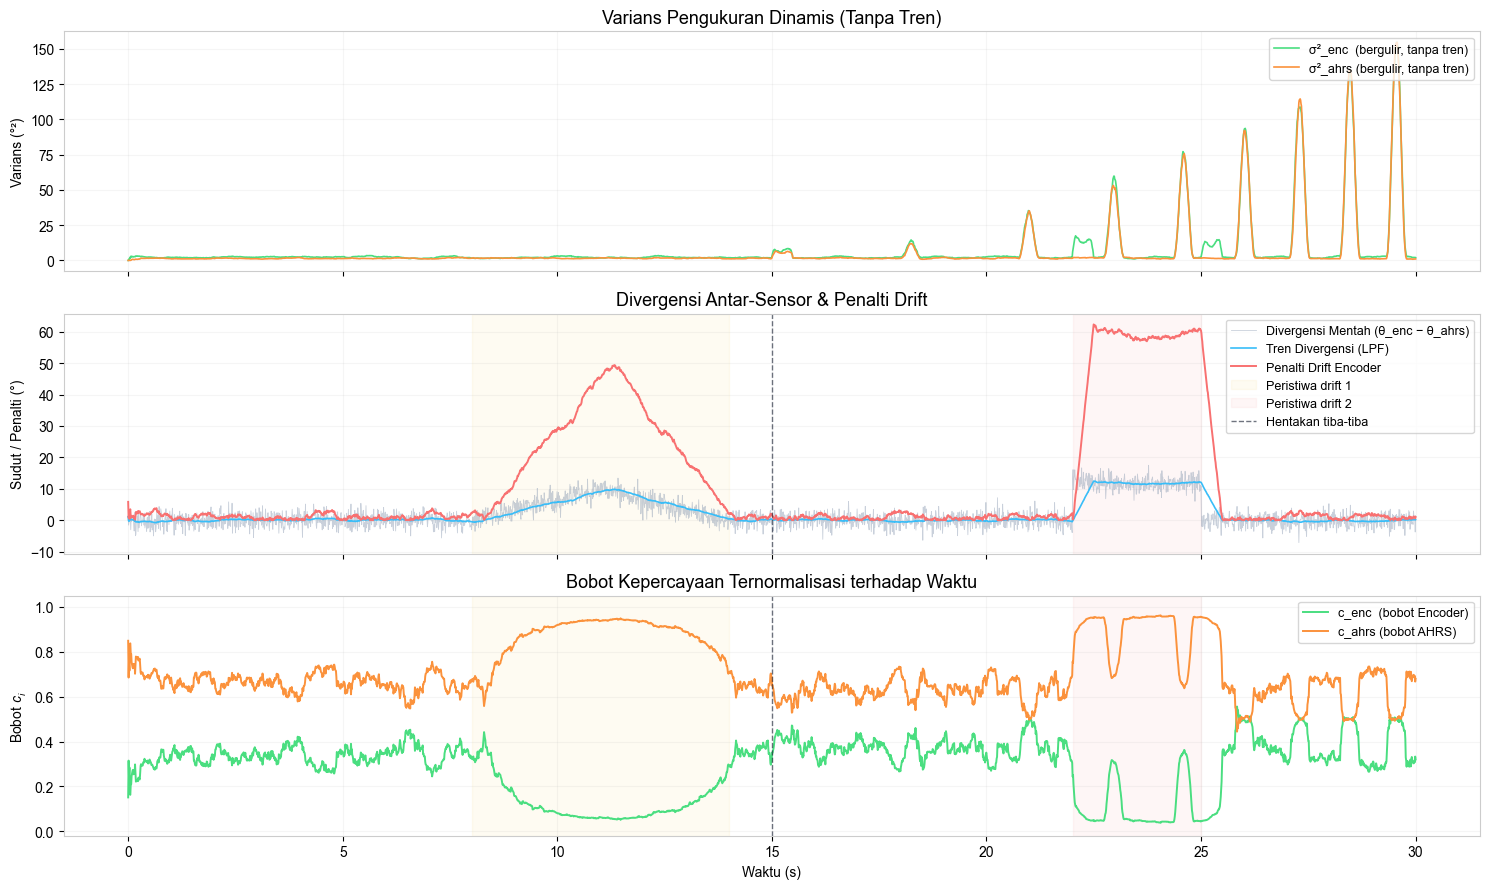

Mean confidence — Encoder: 0.2837  |  AHRS: 0.7163


In [3]:
# ── Prior noise parameters ────────────────────────────────────────────────
sigma_prior_enc  = 1.5   # Encoder prior baseline noise σ (°)
sigma_prior_ahrs = 1.2   # AHRS prior baseline noise σ (°)

# ── Detrended dynamic variance (causal rolling variance) ──────────────────
WINDOW = 50  # samples (= 0.5 s at 100 Hz)

def rolling_variance(data, window):
    """Compute rolling variance on *detrended* data within a causal window.

    A linear trend is fitted and subtracted within each window before
    computing variance. This isolates sensor noise from the physical
    trajectory motion, which would otherwise dominate the estimate.
    """
    n = len(data)
    var = np.zeros(n)
    for i in range(n):
        start = max(0, i - window + 1)
        segment = data[start:i+1]
        seg_len = len(segment)
        if seg_len < 3:
            var[i] = 0.0
        else:
            x = np.arange(seg_len)
            coeffs = np.polyfit(x, segment, 1)
            detrended = segment - np.polyval(coeffs, x)
            var[i] = np.var(detrended)
    return var

var_enc  = rolling_variance(theta_enc,  WINDOW)
var_ahrs = rolling_variance(theta_ahrs, WINDOW)

# ── Sensor divergence & drift penalty ─────────────────────────────────────
divergence = theta_enc - theta_ahrs

# Causal rolling mean low-pass filter to extract drift trend
divergence_trend = np.zeros(N)
for i in range(N):
    start = max(0, i - WINDOW + 1)
    divergence_trend[i] = np.mean(divergence[start:i+1])

drift_penalty_enc  = np.abs(divergence_trend) * 5.0
drift_penalty_ahrs = 0.0

# ── Inverse variance confidence scoring ───────────────────────────────────
c_enc_raw  = 1.0 / (sigma_prior_enc**2  + var_enc  + drift_penalty_enc  + 1e-5)
c_ahrs_raw = 1.0 / (sigma_prior_ahrs**2 + var_ahrs + drift_penalty_ahrs + 1e-5)

# Normalized weights (c_enc + c_ahrs = 1)
c_enc  = c_enc_raw  / (c_enc_raw + c_ahrs_raw)
c_ahrs = c_ahrs_raw / (c_enc_raw + c_ahrs_raw)

# ── Plots ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(15, 9), sharex=True)

# Panel 1: Rolling variance
axes[0].plot(t, var_enc,  color='#4ade80', lw=1.2, label='σ²_enc  (bergulir, tanpa tren)')
axes[0].plot(t, var_ahrs, color='#fb923c', lw=1.2, label='σ²_ahrs (bergulir, tanpa tren)')
axes[0].set_title('Varians Pengukuran Dinamis (Tanpa Tren)', fontsize=13)
axes[0].set_ylabel('Varians (°²)')
axes[0].legend(loc='upper right', fontsize=9); axes[0].grid(alpha=0.12)

# Panel 2: Divergence and drift penalty
axes[1].plot(t, divergence, color='#94a3b8', lw=0.6, alpha=0.5, label='Divergensi Mentah (θ_enc − θ_ahrs)')
axes[1].plot(t, divergence_trend, color='#38bdf8', lw=1.2, label='Tren Divergensi (LPF)')
axes[1].plot(t, drift_penalty_enc, color='#f87171', lw=1.4, label='Penalti Drift Encoder')
mark_events(axes[1], label=True)
axes[1].set_title('Divergensi Antar-Sensor & Penalti Drift', fontsize=13)
axes[1].set_ylabel('Sudut / Penalti (°)')
axes[1].legend(loc='upper right', fontsize=9); axes[1].grid(alpha=0.12)

# Panel 3: Normalized confidence weights
axes[2].plot(t, c_enc,  color='#4ade80', lw=1.4, label='c_enc  (bobot Encoder)')
axes[2].plot(t, c_ahrs, color='#fb923c', lw=1.4, label='c_ahrs (bobot AHRS)')
mark_events(axes[2])
axes[2].set_title('Bobot Kepercayaan Ternormalisasi terhadap Waktu', fontsize=13)
axes[2].set_xlabel('Waktu (s)'); axes[2].set_ylabel('Bobot $c_i$')
axes[2].set_ylim(-0.02, 1.05)
axes[2].legend(loc='upper right', fontsize=9); axes[2].grid(alpha=0.12)

plt.tight_layout()
plt.show()

print(f'Mean confidence — Encoder: {c_enc.mean():.4f}  |  AHRS: {c_ahrs.mean():.4f}')

---
## 4. Direct Confidence-Weighted Angle Fusion

For a single-axis rotation $[-90^\circ, +90^\circ]$, 3D quaternion transformations are unnecessary:
- Single-axis 1D rotation has no gimbal lock or spatial singularities.
- Converting angles to quaternions, averaging, and mapping back via `arctan2` introduces non-linear distortion and unnecessary computational overhead.

The optimal fused angle is computed directly in the angle domain via vectorized weighted sum:

$$\theta_{fused} = c_{enc} \cdot \theta_{enc} + c_{ahrs} \cdot \theta_{ahrs}$$

Since $c_{enc} + c_{ahrs} = 1$, this represents a valid convex combination of sensor estimates.

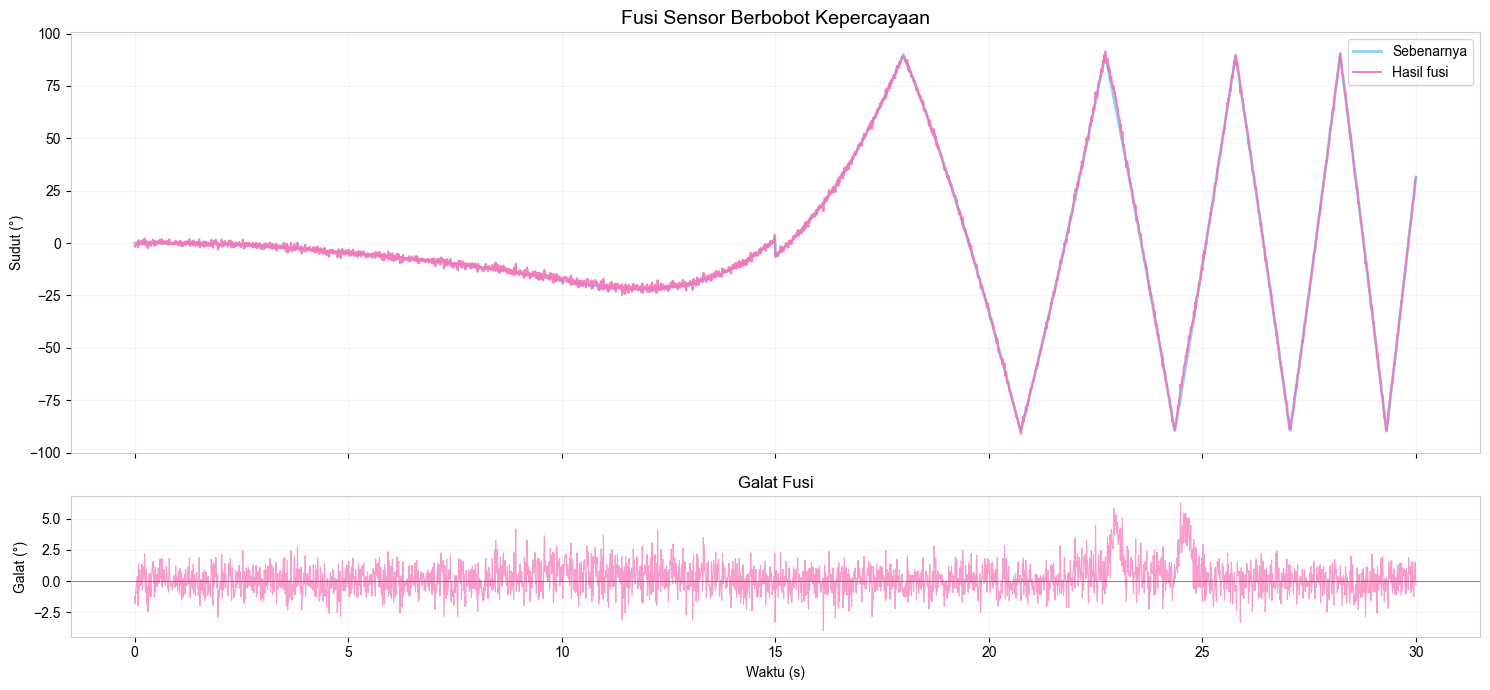

RMSE  Encoder : 4.794°
RMSE  AHRS    : 1.231°
RMSE  Fused   : 1.184°
Improvement over Encoder : +75.3%
Improvement over AHRS    : +3.9%


In [4]:
# ── Direct 1D confidence-weighted angle fusion ────────────────────────────
theta_fused = c_enc * theta_enc + c_ahrs * theta_ahrs

# ── Error analysis ────────────────────────────────────────────────────────
err_enc   = theta_enc   - theta_true
err_ahrs  = theta_ahrs  - theta_true
err_fused = theta_fused - theta_true

rmse_enc   = np.sqrt(np.mean(err_enc**2))
rmse_ahrs  = np.sqrt(np.mean(err_ahrs**2))
rmse_fused = np.sqrt(np.mean(err_fused**2))

# ── Plot: fused vs true ──────────────────────────────────────────────────
fig, axes = plt.subplots(2, 1, figsize=(15, 7), sharex=True,
                         gridspec_kw={'height_ratios': [3, 1]})

axes[0].plot(t, theta_true,  color='#38bdf8', lw=2.0, alpha=0.6, label='Sebenarnya')
axes[0].plot(t, theta_fused, color='#f472b6', lw=1.5, alpha=0.9, label='Hasil fusi')
axes[0].set_title('Fusi Sensor Berbobot Kepercayaan', fontsize=14)
axes[0].set_ylabel('Sudut (°)')
axes[0].legend(loc='upper right'); axes[0].grid(alpha=0.12)

axes[1].plot(t, err_fused, color='#f472b6', lw=0.8, alpha=0.7)
axes[1].axhline(y=0, color='#475569', ls='-', lw=0.5)
axes[1].set_title('Galat Fusi', fontsize=12)
axes[1].set_xlabel('Waktu (s)'); axes[1].set_ylabel('Galat (°)')
axes[1].grid(alpha=0.12)

plt.tight_layout()
plt.show()

print(f'RMSE  Encoder : {rmse_enc:.3f}°')
print(f'RMSE  AHRS    : {rmse_ahrs:.3f}°')
print(f'RMSE  Fused   : {rmse_fused:.3f}°')
print(f'Improvement over Encoder : {(1 - rmse_fused/rmse_enc)*100:+.1f}%')
print(f'Improvement over AHRS    : {(1 - rmse_fused/rmse_ahrs)*100:+.1f}%')

---
## 5. Extended Kalman Filter (EKF) Baseline

To judge the confidence-score approach against a standard baseline, we fuse the **same two sensor
streams** with an Extended Kalman Filter. The two methods work differently:

| | Confidence-score fusion | EKF |
|---|---|---|
| Fused estimate | Convex combination of the two readings at each sample | Recursive state estimate from a motion model + both readings |
| Drift handling | Down-weights the encoder while it diverges from the AHRS | Estimates the encoder bias as a state and subtracts it |
| Memory | Sliding windows ($W = 50$) | Full history through the covariance $\mathbf{P}$ |
| Tuning knobs | Window $W$, drift-penalty gain | Process noise $q_{acc}$, $q_{bias}$ |

From here on, every analysis figure shows **both** fused estimates: confidence fusion in pink and the EKF in violet.

**Sudden jolt.** Right after the jolt the two methods behave differently. The confidence fusion is a convex
combination of two readings that both jump, so it follows the step at once. The EKF's constant-velocity model
treats the step as an outlier and needs several samples to catch up. The cell below measures this
**confidence-fusion-best window**: the time after the jolt until the EKF has recovered, i.e. while the
confidence fusion's RMSE over the next 0.1 s is still below the EKF's. Every figure from §6 onward shades it in green.

### State & models
$$\mathbf{x} = \begin{bmatrix} \theta & \omega & b_{enc} \end{bmatrix}^T$$

Process model (constant velocity, random-walk encoder bias):
$$f(\mathbf{x}) = \begin{bmatrix} \theta + \omega\,\Delta t \\ \omega \\ b_{enc} \end{bmatrix}$$

Measurement model (the AHRS is assumed drift-free, the same assumption the confidence method makes):
$$h(\mathbf{x}) = \begin{bmatrix} \theta + b_{enc} \\ \theta \end{bmatrix}, \qquad
\mathbf{R} = \mathrm{diag}(\sigma_{prior,enc}^2,\ \sigma_{prior,ahrs}^2)$$

Process noise uses the continuous white-acceleration model plus a bias random walk:
$$\mathbf{Q} = \begin{bmatrix} q_{acc}\frac{\Delta t^3}{3} & q_{acc}\frac{\Delta t^2}{2} & 0 \\
q_{acc}\frac{\Delta t^2}{2} & q_{acc}\,\Delta t & 0 \\ 0 & 0 & q_{bias}\,\Delta t \end{bmatrix}$$

### EKF recursion
$$\hat{\mathbf{x}}^- = f(\hat{\mathbf{x}}), \quad \mathbf{P}^- = \mathbf{F}\mathbf{P}\mathbf{F}^T + \mathbf{Q}, \quad \mathbf{F} = \frac{\partial f}{\partial \mathbf{x}}$$
$$\mathbf{K} = \mathbf{P}^-\mathbf{H}^T(\mathbf{H}\mathbf{P}^-\mathbf{H}^T + \mathbf{R})^{-1}, \quad \mathbf{H} = \frac{\partial h}{\partial \mathbf{x}}$$
$$\hat{\mathbf{x}} = \hat{\mathbf{x}}^- + \mathbf{K}\big(\mathbf{z} - h(\hat{\mathbf{x}}^-)\big), \quad
\mathbf{P} = (\mathbf{I}-\mathbf{K}\mathbf{H})\mathbf{P}^-(\mathbf{I}-\mathbf{K}\mathbf{H})^T + \mathbf{K}\mathbf{R}\mathbf{K}^T$$

> **Note on linearity.** For this single-axis model $f$ and $h$ are linear, so the Jacobians are
> constant and the EKF gives exactly the same result as a linear Kalman filter. The code is still written in
> EKF form ($f$, $h$, and their Jacobians) so it extends directly to the 3-axis antenna, where the
> forward kinematics make $h$ non-linear.

In [5]:
# ══════════════════════════════════════════════════════════════════════════
#  EXTENDED KALMAN FILTER — angle, angular rate, and encoder bias
# ══════════════════════════════════════════════════════════════════════════

def ekf_f(x):
    """Process model: constant velocity, constant (random-walk) encoder bias."""
    return np.array([x[0] + x[1] * dt, x[1], x[2]])

def ekf_F(x):
    """Jacobian of the process model."""
    return np.array([[1.0, dt, 0.0],
                     [0.0, 1.0, 0.0],
                     [0.0, 0.0, 1.0]])

def ekf_h(x):
    """Measurement model: z = [encoder, AHRS]."""
    return np.array([x[0] + x[2], x[0]])

def ekf_H(x):
    """Jacobian of the measurement model."""
    return np.array([[1.0, 0.0, 1.0],
                     [1.0, 0.0, 0.0]])

def ekf_Q(q_acc, q_bias):
    """Continuous white-acceleration noise on (θ, ω) plus a bias random walk."""
    return np.array([[q_acc * dt**3 / 3, q_acc * dt**2 / 2, 0.0],
                     [q_acc * dt**2 / 2, q_acc * dt,        0.0],
                     [0.0,               0.0,               q_bias * dt]])

def run_ekf(z_enc, z_ahrs, q_acc, q_bias):
    """Run the EKF causally over both sensor streams; returns the state history and its 1σ bounds."""
    n = len(z_enc)
    Q = ekf_Q(q_acc, q_bias)
    R = np.diag([sigma_prior_enc**2, sigma_prior_ahrs**2])  # same priors as the confidence method
    I = np.eye(3)

    x = np.array([z_ahrs[0], 0.0, 0.0])                     # start at the drift-free sensor
    P = np.diag([sigma_prior_ahrs**2, 50.0**2, 2.0**2])

    xs = np.zeros((n, 3))
    sd = np.zeros((n, 3))
    for k in range(n):
        if k > 0:                                            # predict
            F = ekf_F(x)
            x = ekf_f(x)
            P = F @ P @ F.T + Q
        H = ekf_H(x)                                         # update
        y = np.array([z_enc[k], z_ahrs[k]]) - ekf_h(x)
        S = H @ P @ H.T + R
        K = P @ H.T @ np.linalg.inv(S)
        x = x + K @ y
        IKH = I - K @ H
        P = IKH @ P @ IKH.T + K @ R @ K.T                    # Joseph form: keeps P symmetric PSD
        xs[k] = x
        sd[k] = np.sqrt(np.diag(P))
    return xs, sd

# ── Process noise (chosen from the sensitivity sweep in §9.1) ─────────────
q_acc  = 1e4   # (°/s²)²·s — large on purpose: the ±90° wall bounces reverse ω within one step
q_bias = 10.0  # °²/s      — lets the bias estimate follow the drift ramp and the 12° glitch

C_EKF = '#8b5cf6'  # EKF series colour (violet) in every comparison plot

ekf_states, ekf_sd = run_ekf(theta_enc, theta_ahrs, q_acc, q_bias)
theta_ekf = ekf_states[:, 0]
omega_ekf = ekf_states[:, 1]
bias_ekf  = ekf_states[:, 2]
err_ekf   = theta_ekf - theta_true

# ── Sudden-jolt response: the window after the jolt where the confidence fusion beats the EKF ──
# For each sample in the 1 s after the jolt, compare the RMSE over the next 0.1 s; the window lasts
# until the EKF has recovered, i.e. until its forward RMSE drops below the confidence fusion's.
JOLT_LOOK = 10  # samples (0.1 s)
fwd_rmse = lambda e: np.array([np.sqrt(np.mean(e[k:k + JOLT_LOOK]**2)) for k in range(JOLT_IDX, JOLT_IDX + 100)])
conf_ahead = fwd_rmse(err_fused) < fwd_rmse(err_ekf)
JOLT_WIN = len(conf_ahead) if conf_ahead.all() else int(np.argmin(conf_ahead))  # samples
jolt_seg = slice(JOLT_IDX, JOLT_IDX + max(JOLT_WIN, 1))
C_JOLT = '#10b981'  # confidence-fusion-best window (green)

def mark_jolt_win(ax, label=False, note=False, note_y=0.92):
    """Shade the post-jolt window where the confidence fusion is more accurate than the EKF."""
    if JOLT_WIN == 0:
        return
    ax.axvspan(t[JOLT_IDX], t[JOLT_IDX + JOLT_WIN - 1], color=C_JOLT, alpha=0.25,
               label='Hentakan: fusi kepercayaan terbaik' if label else None)
    if note:
        ax.annotate(f'Hentakan tiba-tiba - fusi kepercayaan terbaik\nselama {JOLT_WIN*dt:.2f}s',
                    xy=(t[JOLT_IDX], note_y), xycoords=('data', 'axes fraction'),
                    xytext=(-12, 0), textcoords='offset points', ha='right', va='center',
                    fontsize=9, color='#047857', fontweight='bold',
                    arrowprops=dict(arrowstyle='->', color='#047857', lw=1.0))

print(f'EKF  q_acc = {q_acc:g}  |  q_bias = {q_bias:g}')
print(f'RMSE  Confidence fusion : {np.sqrt(np.mean(err_fused**2)):.3f}°')
print(f'RMSE  EKF               : {np.sqrt(np.mean(err_ekf**2)):.3f}°')
print(f'Sudden jolt at t = {t[JOLT_IDX]:.1f}s: confidence fusion beats the EKF for the first '
      f'{JOLT_WIN} samples ({JOLT_WIN*dt:.2f}s)  |  RMSE in that window: '
      f'confidence {np.sqrt(np.mean(err_fused[jolt_seg]**2)):.3f}°, EKF {np.sqrt(np.mean(err_ekf[jolt_seg]**2)):.3f}°')


EKF  q_acc = 10000  |  q_bias = 10
RMSE  Confidence fusion : 1.184°
RMSE  EKF               : 0.671°
Sudden jolt at t = 15.0s: confidence fusion beats the EKF for the first 8 samples (0.08s)  |  RMSE in that window: confidence 0.739°, EKF 1.990°


---
## 6. Final Preview — Full Pipeline Visualization

A consolidated 4-panel view of the entire fusion pipeline, with the EKF baseline alongside:

1. **Ground Truth** — the true physical rotation
2. **Noisy Sensor Readings** — Encoder (with drift events) and AHRS
3. **Confidence Scores** — dynamic per-sensor trust values
4. **Fused Outputs vs Ground Truth** — confidence fusion and EKF overlaid on truth

Drift events are shaded yellow / red, the sudden jolt is the dashed line, and the green band right after it is
the window where the confidence fusion beats the EKF.

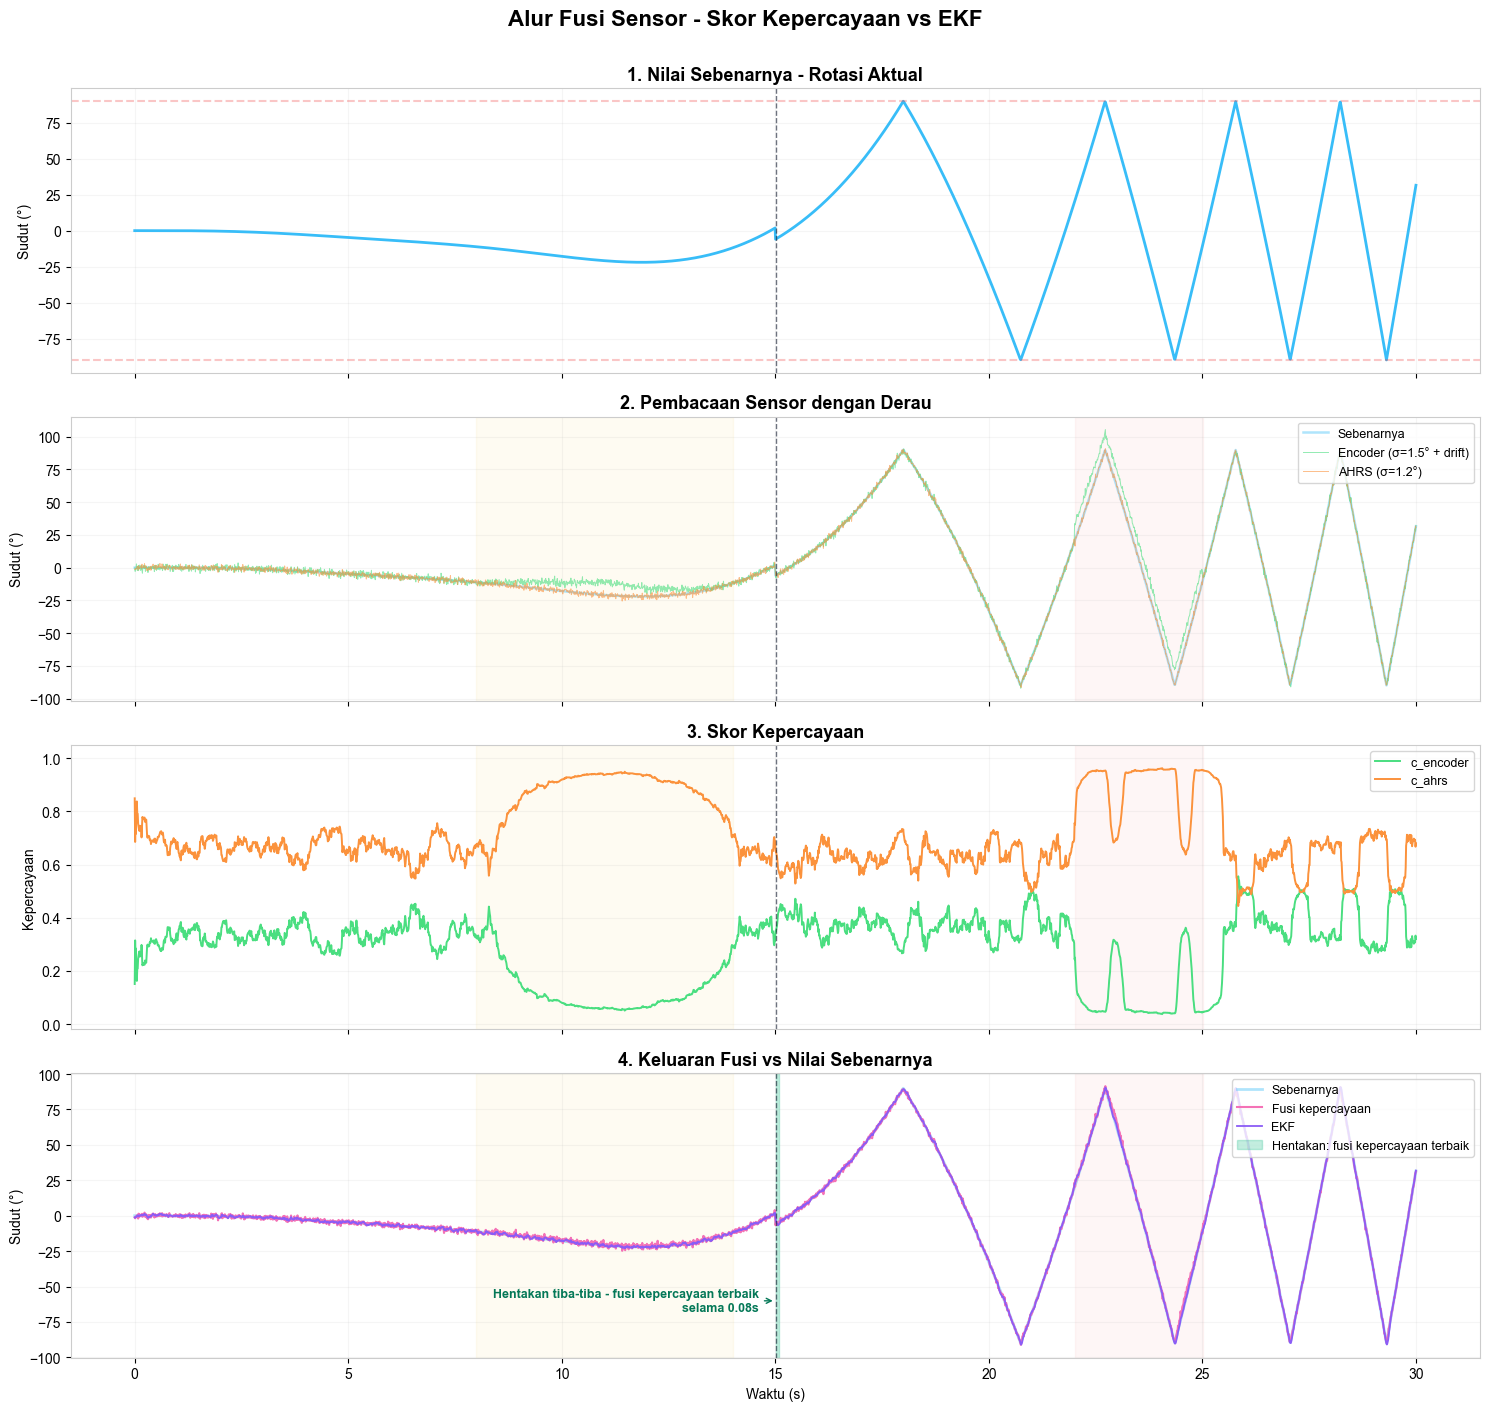

In [6]:
fig, axes = plt.subplots(4, 1, figsize=(15, 14), sharex=True)

# -- Panel 1: Ground truth
axes[0].plot(t, theta_true, color='#38bdf8', lw=2)
axes[0].axhline(y= 90, color='#ef4444', ls='--', alpha=0.3)
axes[0].axhline(y=-90, color='#ef4444', ls='--', alpha=0.3)
axes[0].axvline(t[JOLT_IDX], color='#0f172a', ls='--', lw=1.0, alpha=0.6)
axes[0].set_title('1. Nilai Sebenarnya - Rotasi Aktual', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Sudut (°)'); axes[0].grid(alpha=0.12)

# -- Panel 2: Noisy sensor readings
axes[1].plot(t, theta_true, color='#38bdf8', lw=1.8, alpha=0.4, label='Sebenarnya')
axes[1].plot(t, theta_enc,  color='#4ade80', lw=0.7, alpha=0.6,
             label=f'Encoder (σ={sigma_enc}° + drift)')
axes[1].plot(t, theta_ahrs, color='#fb923c', lw=0.7, alpha=0.6,
             label=f'AHRS (σ={sigma_ahrs}°)')
mark_events(axes[1])
axes[1].set_title('2. Pembacaan Sensor dengan Derau', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Sudut (°)')
axes[1].legend(loc='upper right', fontsize=9); axes[1].grid(alpha=0.12)

# -- Panel 3: Confidence scores
axes[2].plot(t, c_enc,  color='#4ade80', lw=1.4, label='c_encoder')
axes[2].plot(t, c_ahrs, color='#fb923c', lw=1.4, label='c_ahrs')
mark_events(axes[2])
axes[2].set_title('3. Skor Kepercayaan', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Kepercayaan'); axes[2].set_ylim(-0.02, 1.05)
axes[2].legend(loc='upper right', fontsize=9); axes[2].grid(alpha=0.12)

# -- Panel 4: Fused output
axes[3].plot(t, theta_true,  color='#38bdf8', lw=2, alpha=0.4, label='Sebenarnya')
axes[3].plot(t, theta_fused, color='#f472b6', lw=1.5, label='Fusi kepercayaan')
axes[3].fill_between(t, theta_true, theta_fused, alpha=0.12, color='#f472b6')
axes[3].plot(t, theta_ekf,   color=C_EKF,     lw=1.3, label='EKF')
mark_events(axes[3])
mark_jolt_win(axes[3], label=True, note=True, note_y=0.2)
axes[3].set_title('4. Keluaran Fusi vs Nilai Sebenarnya', fontsize=13, fontweight='bold')
axes[3].set_xlabel('Waktu (s)'); axes[3].set_ylabel('Sudut (°)')
axes[3].legend(loc='upper right', fontsize=9); axes[3].grid(alpha=0.12)

fig.suptitle('Alur Fusi Sensor - Skor Kepercayaan vs EKF',
             fontsize=16, fontweight='bold', y=1.005)
plt.tight_layout()
plt.show()


---
## 7. Accuracy Analysis Over Time

To understand **how the fusion quality evolves** during operation, we compute
**rolling (windowed) accuracy metrics** for each signal against ground truth.

This reveals:
- How the fused output reacts to encoder **drift events** (highlighted regions)
- How each fusion method handles the **sudden jolt** (dashed line), and where the confidence fusion beats the EKF (green band)
- Whether the fusion maintains consistent accuracy or degrades in certain conditions
- The instantaneous error magnitude at every timestep

### Plots
1. **Instantaneous Absolute Error** — per-sample |estimated - true| for both sensors and both fusion methods
2. **Rolling RMSE** — windowed RMS error showing local accuracy trends
3. **Rolling R-squared** — windowed coefficient of determination (1.0 = perfect tracking)


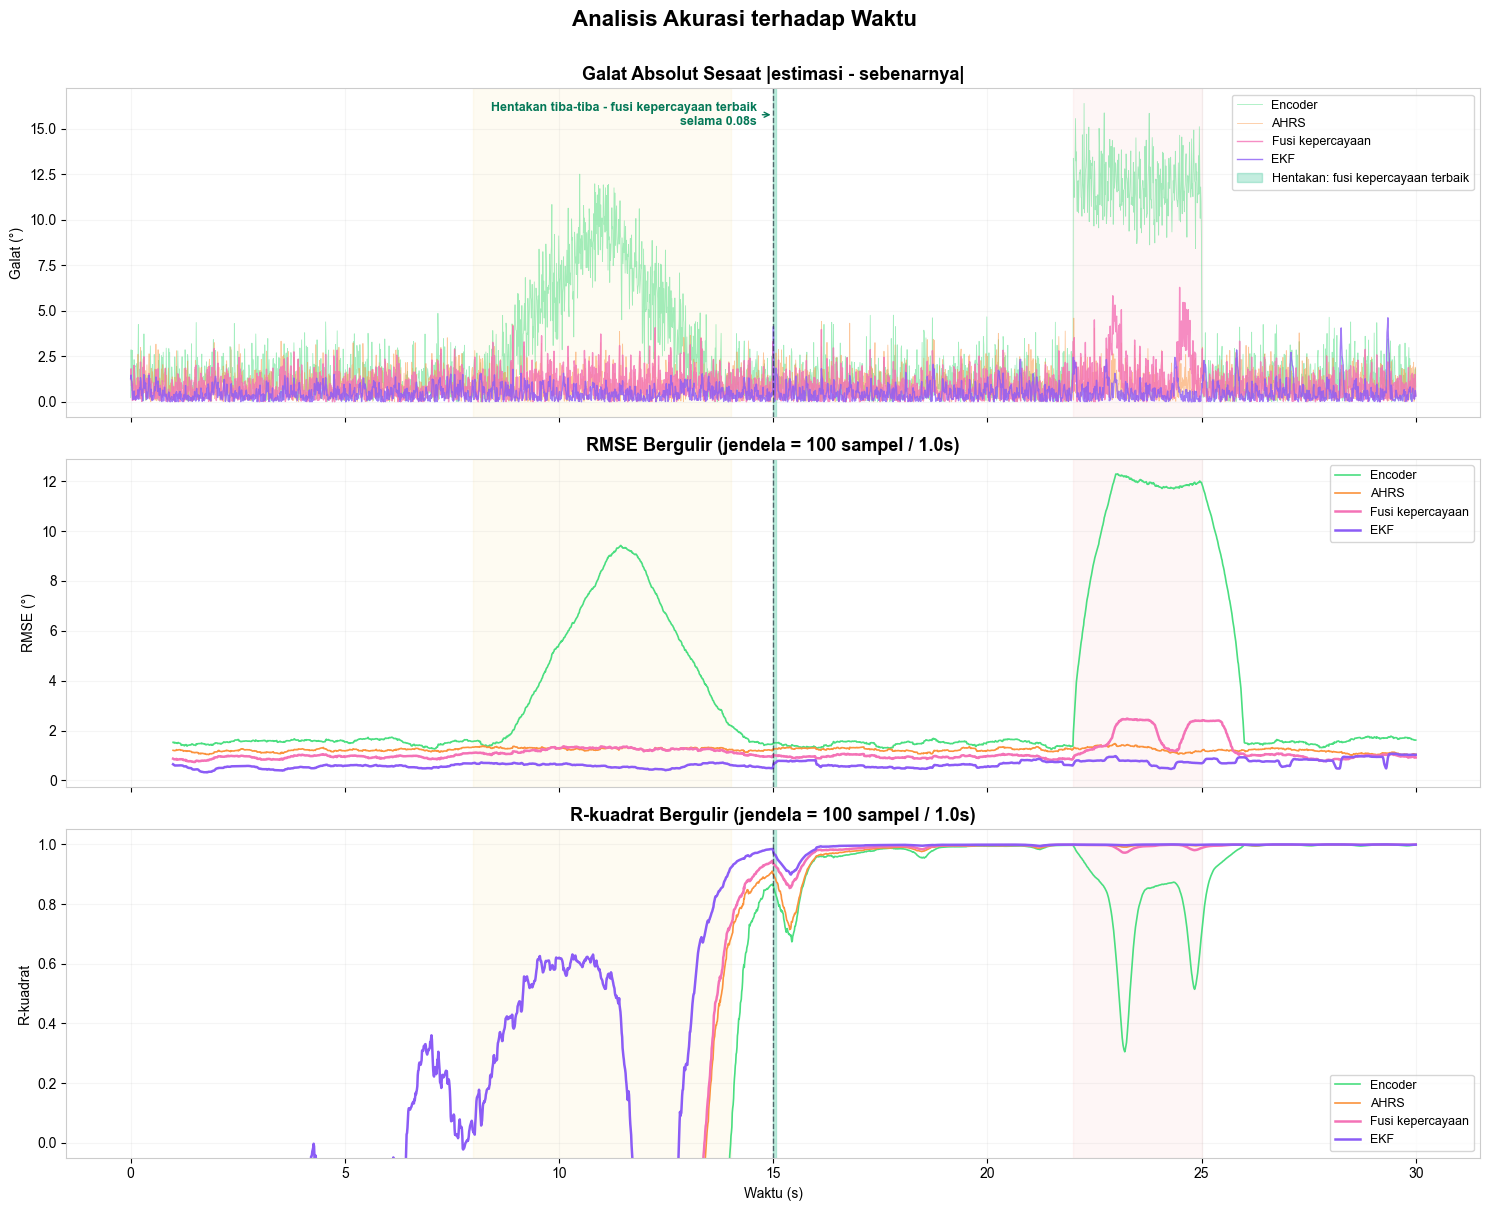

Accuracy window: 100 samples (1.0s)
Confidence fusion  beats both raw sensors (rolling RMSE) for 2398/3000 samples (79.9% of the time)
EKF                beats both raw sensors (rolling RMSE) for 2892/3000 samples (96.4% of the time)
EKF has lower rolling RMSE than confidence fusion for 2791/3000 samples (93.0% of the time)


In [7]:
# ══════════════════════════════════════════════════════════════════════════
#  ROLLING ACCURACY METRICS
# ══════════════════════════════════════════════════════════════════════════

ACCURACY_WINDOW = 100  # samples (= 1.0 s at 100 Hz)

def rolling_rmse(true, estimated, window):
    """Compute rolling RMSE with a causal sliding window."""
    n = len(true)
    result = np.full(n, np.nan)
    for i in range(window - 1, n):
        start = i - window + 1
        err = estimated[start:i+1] - true[start:i+1]
        result[i] = np.sqrt(np.mean(err**2))
    return result

def rolling_r2(true, estimated, window):
    """Compute rolling R-squared with a causal sliding window."""
    n = len(true)
    result = np.full(n, np.nan)
    for i in range(window - 1, n):
        start = i - window + 1
        seg_true = true[start:i+1]
        seg_est  = estimated[start:i+1]
        ss_res = np.sum((seg_est - seg_true)**2)
        ss_tot = np.sum((seg_true - np.mean(seg_true))**2)
        result[i] = 1.0 - ss_res / ss_tot if ss_tot > 0 else np.nan
    return result

# Compute instantaneous absolute errors
abs_err_enc   = np.abs(theta_enc   - theta_true)
abs_err_ahrs  = np.abs(theta_ahrs  - theta_true)
abs_err_fused = np.abs(theta_fused  - theta_true)
abs_err_ekf   = np.abs(theta_ekf    - theta_true)

# Compute rolling metrics
roll_rmse_enc   = rolling_rmse(theta_true, theta_enc,   ACCURACY_WINDOW)
roll_rmse_ahrs  = rolling_rmse(theta_true, theta_ahrs,  ACCURACY_WINDOW)
roll_rmse_fused = rolling_rmse(theta_true, theta_fused, ACCURACY_WINDOW)
roll_rmse_ekf   = rolling_rmse(theta_true, theta_ekf,   ACCURACY_WINDOW)

roll_r2_enc   = rolling_r2(theta_true, theta_enc,   ACCURACY_WINDOW)
roll_r2_ahrs  = rolling_r2(theta_true, theta_ahrs,  ACCURACY_WINDOW)
roll_r2_fused = rolling_r2(theta_true, theta_fused, ACCURACY_WINDOW)
roll_r2_ekf   = rolling_r2(theta_true, theta_ekf,   ACCURACY_WINDOW)

# ── Plots ─────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

# -- Panel 1: Instantaneous absolute error
axes[0].plot(t, abs_err_enc,   color='#4ade80', lw=0.6, alpha=0.5, label='Encoder')
axes[0].plot(t, abs_err_ahrs,  color='#fb923c', lw=0.6, alpha=0.5, label='AHRS')
axes[0].plot(t, abs_err_fused, color='#f472b6', lw=1.0, alpha=0.8, label='Fusi kepercayaan')
axes[0].plot(t, abs_err_ekf,   color=C_EKF,     lw=1.0, alpha=0.8, label='EKF')
mark_events(axes[0])
mark_jolt_win(axes[0], label=True, note=True)
axes[0].set_title('Galat Absolut Sesaat |estimasi - sebenarnya|',
                  fontsize=13, fontweight='bold')
axes[0].set_ylabel('Galat (°)')
axes[0].legend(loc='upper right', fontsize=9); axes[0].grid(alpha=0.12)

# -- Panel 2: Rolling RMSE
axes[1].plot(t, roll_rmse_enc,   color='#4ade80', lw=1.2, label='Encoder')
axes[1].plot(t, roll_rmse_ahrs,  color='#fb923c', lw=1.2, label='AHRS')
axes[1].plot(t, roll_rmse_fused, color='#f472b6', lw=1.8, label='Fusi kepercayaan')
axes[1].plot(t, roll_rmse_ekf,   color=C_EKF,     lw=1.8, label='EKF')
mark_events(axes[1])
mark_jolt_win(axes[1])
axes[1].set_title(f'RMSE Bergulir (jendela = {ACCURACY_WINDOW} sampel / {ACCURACY_WINDOW*dt:.1f}s)',
                  fontsize=13, fontweight='bold')
axes[1].set_ylabel('RMSE (°)')
axes[1].legend(loc='upper right', fontsize=9); axes[1].grid(alpha=0.12)

# -- Panel 3: Rolling R-squared
axes[2].plot(t, roll_r2_enc,   color='#4ade80', lw=1.2, label='Encoder')
axes[2].plot(t, roll_r2_ahrs,  color='#fb923c', lw=1.2, label='AHRS')
axes[2].plot(t, roll_r2_fused, color='#f472b6', lw=1.8, label='Fusi kepercayaan')
axes[2].plot(t, roll_r2_ekf,   color=C_EKF,     lw=1.8, label='EKF')
mark_events(axes[2])
mark_jolt_win(axes[2])
axes[2].set_title(f'R-kuadrat Bergulir (jendela = {ACCURACY_WINDOW} sampel / {ACCURACY_WINDOW*dt:.1f}s)',
                  fontsize=13, fontweight='bold')
axes[2].set_xlabel('Waktu (s)'); axes[2].set_ylabel('R-kuadrat')
axes[2].set_ylim(-0.05, 1.05)
axes[2].legend(loc='lower right', fontsize=9); axes[2].grid(alpha=0.12)

fig.suptitle('Analisis Akurasi terhadap Waktu',
             fontsize=16, fontweight='bold', y=1.005)
plt.tight_layout()
plt.show()

# Summary
print(f'Accuracy window: {ACCURACY_WINDOW} samples ({ACCURACY_WINDOW*dt:.1f}s)')
for name, r in (('Confidence fusion', roll_rmse_fused), ('EKF', roll_rmse_ekf)):
    best = np.nansum((r < roll_rmse_enc) & (r < roll_rmse_ahrs))
    print(f'{name:<18s} beats both raw sensors (rolling RMSE) for {best}/{N} samples ({best/N*100:.1f}% of the time)')
ekf_wins = np.nansum(roll_rmse_ekf < roll_rmse_fused)
print(f'EKF has lower rolling RMSE than confidence fusion for {ekf_wins}/{N} samples ({ekf_wins/N*100:.1f}% of the time)')


---
## 8. Quality Score Card

A comprehensive summary comparing the quality of each signal against ground truth.

| Metric | Definition | Purpose |
|--------|-----------|--------|
| **RMSE** | $\sqrt{\frac{1}{N}\sum(\hat{\theta}-\theta)^2}$ | Overall average error magnitude |
| **MAE** | $\frac{1}{N}\sum|\hat{\theta}-\theta|$ | Average absolute deviation |
| **Max Error** | $\max|\hat{\theta}-\theta|$ | Worst-case instantaneous error |
| **R-squared** | $1 - \frac{\sum(\hat{\theta}-\theta)^2}{\sum(\theta-\bar{\theta})^2}$ | Variance explained (1 = perfect) |
| **SNR (dB)** | $10\log_{10}\frac{\sigma^2_{signal}}{\sigma^2_{error}}$ | Signal-to-noise ratio |
| **Jolt RMSE / Peak** | RMSE and max $|\hat{\theta}-\theta|$ inside the confidence-fusion-best window after the jolt (§5) | Response to a sudden jolt |

The **"Confidence vs Best"** and **"EKF vs Best"** columns show how much each fusion method improves over the
**best individual sensor** for each metric.

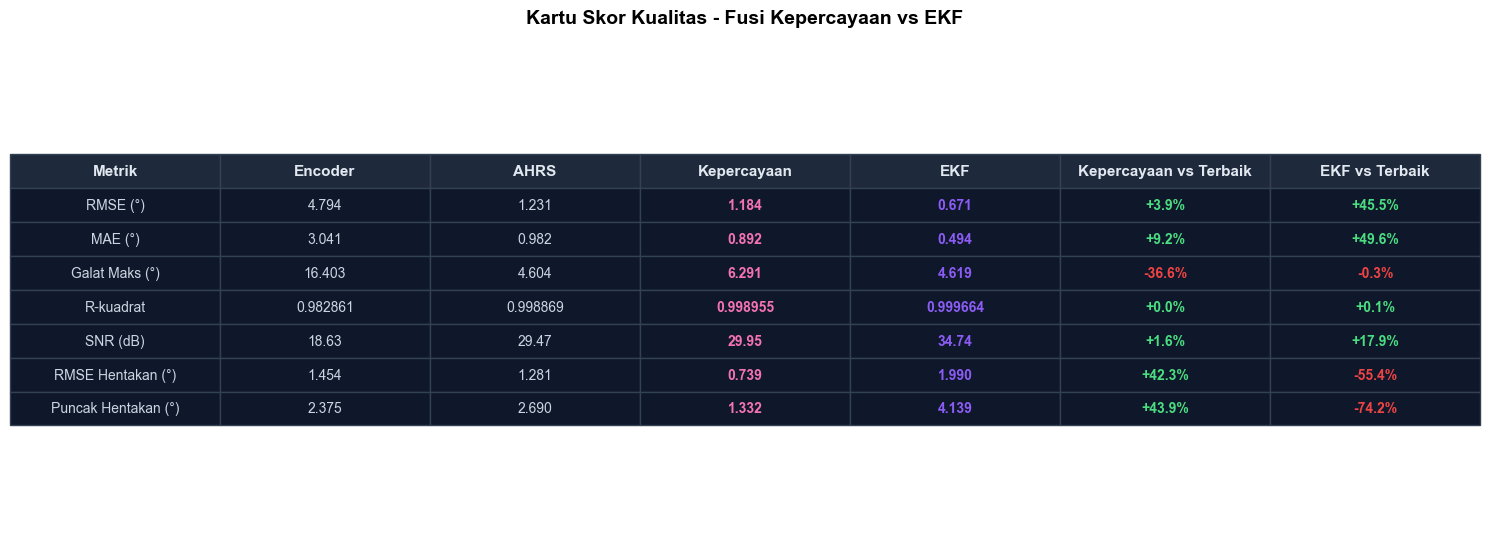

  SENSOR FUSION QUALITY ASSESSMENT - CONFIDENCE SCORE vs EKF
  Duration          : 30s  |  Samples: 3000  |  dt: 0.01s
  Encoder noise     : sigma = 1.5 deg  (+ drift events)
  AHRS noise        : sigma = 1.2 deg
  Rolling window    : 50 samples (0.5s)
  EKF               : q_acc = 10000  |  q_bias = 10
  Sudden jolt       : 8 deg at t = 15.0s  |  jolt window: 0.08s
  --------------------------------------------------------------------
  Metric             Encoder      AHRS  Confidence       EKF  Conf/Best  EKF/Best
  --------------------------------------------------------------------
  RMSE (deg)           4.794     1.231       1.184     0.671      +3.9%    +45.5%
  MAE (deg)            3.041     0.982       0.892     0.494      +9.2%    +49.6%
  Max Error (deg)     16.403     4.604       6.291     4.619     -36.6%     -0.3%
  R-squared         0.982861  0.998869    0.998955  0.999664      +0.0%     +0.1%
  SNR (dB)             18.63     29.47       29.95     34.74      +1.6%    +17.

'D:\\Reza Fauzan\\Anduril Industries\\simulation\\logs\\sim_timeseries_20261008_160437.csv'

In [8]:
# ══════════════════════════════════════════════════════════════════════════
#  QUALITY METRICS FUNCTIONS
# ══════════════════════════════════════════════════════════════════════════

def compute_metrics(true, estimated, label):
    """Compute a full suite of quality metrics for a sensor/fused signal."""
    error = estimated - true
    abs_error = np.abs(error)

    rmse = np.sqrt(np.mean(error**2))
    mae  = np.mean(abs_error)
    max_err = np.max(abs_error)

    # R-squared (coefficient of determination)
    ss_res = np.sum(error**2)
    ss_tot = np.sum((true - np.mean(true))**2)
    r2 = 1.0 - ss_res / ss_tot if ss_tot > 0 else float('nan')

    # Signal-to-Noise Ratio (dB)
    signal_var = np.var(true)
    error_var  = np.var(error)
    snr_db = 10.0 * np.log10(signal_var / error_var) if error_var > 0 else float('inf')

    return {
        'label':     label,
        'rmse':      rmse,
        'mae':       mae,
        'max_error': max_err,
        'r2':        r2,
        'snr_db':    snr_db,
    }

def improvement_str(raw_val, fused_val, lower_better=True):
    """Format an improvement percentage string."""
    if lower_better:
        pct = (1.0 - fused_val / raw_val) * 100.0 if raw_val != 0 else 0.0
    else:
        pct = (fused_val / raw_val - 1.0) * 100.0 if raw_val != 0 else 0.0
    sign = '+' if pct >= 0 else ''
    return f'{sign}{pct:.1f}%'

# Compute metrics
m_enc   = compute_metrics(theta_true, theta_enc,   'Encoder')
m_ahrs  = compute_metrics(theta_true, theta_ahrs,  'AHRS')
m_fused = compute_metrics(theta_true, theta_fused, 'Confidence')
m_ekf   = compute_metrics(theta_true, theta_ekf,   'EKF')

# Sudden-jolt response: error inside the confidence-fusion-best window (§5)
for m, est in ((m_enc, theta_enc), (m_ahrs, theta_ahrs), (m_fused, theta_fused), (m_ekf, theta_ekf)):
    e = est[jolt_seg] - theta_true[jolt_seg]
    m['jolt_rmse'] = np.sqrt(np.mean(e**2))
    m['jolt_peak'] = np.max(np.abs(e))

# Best raw sensor per metric
best_rmse = min(m_enc['rmse'], m_ahrs['rmse'])
best_mae  = min(m_enc['mae'],  m_ahrs['mae'])
best_max  = min(m_enc['max_error'], m_ahrs['max_error'])
best_r2   = max(m_enc['r2'],   m_ahrs['r2'])
best_snr  = max(m_enc['snr_db'], m_ahrs['snr_db'])
best_jolt_rmse = min(m_enc['jolt_rmse'], m_ahrs['jolt_rmse'])
best_jolt_peak = min(m_enc['jolt_peak'], m_ahrs['jolt_peak'])

# ══════════════════════════════════════════════════════════════════════════
#  VISUAL SCORE CARD
# ══════════════════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(15, 5.5))
ax.axis('off')

col_labels = ['Metrik', 'Encoder', 'AHRS', 'Kepercayaan', 'EKF', 'Kepercayaan vs Terbaik', 'EKF vs Terbaik']
METRIC_ID = {  # metric names shown in the table figure
    'RMSE (deg)': 'RMSE (°)', 'MAE (deg)': 'MAE (°)', 'Max Error (deg)': 'Galat Maks (°)',
    'R-squared': 'R-kuadrat', 'SNR (dB)': 'SNR (dB)',
    'Jolt RMSE (deg)': 'RMSE Hentakan (°)', 'Jolt Peak (deg)': 'Puncak Hentakan (°)',
}
metric_rows = [  # (label, key, format, lower is better, best raw sensor)
    ('RMSE (deg)',      'rmse',      '{:.3f}', True,  best_rmse),
    ('MAE (deg)',       'mae',       '{:.3f}', True,  best_mae),
    ('Max Error (deg)', 'max_error', '{:.3f}', True,  best_max),
    ('R-squared',       'r2',        '{:.6f}', False, best_r2),
    ('SNR (dB)',        'snr_db',    '{:.2f}', False, best_snr),
    ('Jolt RMSE (deg)', 'jolt_rmse', '{:.3f}', True,  best_jolt_rmse),
    ('Jolt Peak (deg)', 'jolt_peak', '{:.3f}', True,  best_jolt_peak),
]
row_data = [
    [METRIC_ID[name]] + [fmt.format(m[key]) for m in (m_enc, m_ahrs, m_fused, m_ekf)]
    + [improvement_str(best, m[key], lower_better=lower) for m in (m_fused, m_ekf)]
    for name, key, fmt, lower, best in metric_rows
]

table = ax.table(
    cellText=row_data, colLabels=col_labels,
    cellLoc='center', loc='center',
    colColours=['#1e293b'] * len(col_labels)
)
table.auto_set_font_size(False)
table.set_fontsize(11)
table.scale(1.0, 1.8)

for (row, col), cell in table.get_celld().items():
    cell.set_edgecolor('#334155')
    if row == 0:
        cell.set_text_props(color='#e2e8f0', fontweight='bold', fontsize=11)
        cell.set_facecolor('#1e293b')
    else:
        cell.set_facecolor('#0f172a')
        cell.set_text_props(color='#cbd5e1', fontsize=10)
        if col == 3:
            cell.set_text_props(color='#f472b6', fontweight='bold', fontsize=10)
        if col == 4:
            cell.set_text_props(color=C_EKF, fontweight='bold', fontsize=10)
        if col >= 5:
            text = cell.get_text().get_text()
            if text.startswith('+'):
                cell.set_text_props(color='#4ade80', fontweight='bold', fontsize=10)
            elif text.startswith('-'):
                cell.set_text_props(color='#ef4444', fontweight='bold', fontsize=10)

ax.set_title('Kartu Skor Kualitas - Fusi Kepercayaan vs EKF',
             fontsize=14, fontweight='bold', pad=20)
plt.tight_layout()
plt.show()

# ── Console Summary ──────────────────────────────────────────────────────
print('=' * 72)
print('  SENSOR FUSION QUALITY ASSESSMENT - CONFIDENCE SCORE vs EKF')
print('=' * 72)
print(f'  Duration          : {T:.0f}s  |  Samples: {N}  |  dt: {dt}s')
print(f'  Encoder noise     : sigma = {sigma_enc} deg  (+ drift events)')
print(f'  AHRS noise        : sigma = {sigma_ahrs} deg')
print(f'  Rolling window    : {WINDOW} samples ({WINDOW*dt:.1f}s)')
print(f'  EKF               : q_acc = {q_acc:g}  |  q_bias = {q_bias:g}')
print(f'  Sudden jolt       : {JOLT_AMP:g} deg at t = {t[JOLT_IDX]:.1f}s  |  jolt window: {JOLT_WIN*dt:.2f}s')
print(f'  ' + '-' * 68)
print(f'  {"Metric":<16s} {"Encoder":>9s} {"AHRS":>9s} {"Confidence":>11s} {"EKF":>9s} {"Conf/Best":>10s} {"EKF/Best":>9s}')
print(f'  ' + '-' * 68)
for name, key, fmt, lower, best in metric_rows:
    vals = ''.join(f'{fmt.format(m[key]):>{w}s}' for m, w in ((m_enc, 10), (m_ahrs, 10), (m_fused, 12), (m_ekf, 10)))
    print(f'  {name:<16s}{vals} {improvement_str(best, m_fused[key], lower):>10s} {improvement_str(best, m_ekf[key], lower):>9s}')
print(f'  ' + '-' * 68)
print(f'\n  FUSION QUALITY VERDICT (vs best raw sensor):')
for m in (m_fused, m_ekf):
    for name, key, better, best, fmt in (('RMSE', 'rmse', m['rmse'] < best_rmse, best_rmse, '{:.3f} deg'),
                                         ('R-squared', 'r2', m['r2'] > best_r2, best_r2, '{:.6f}'),
                                         ('SNR', 'snr_db', m['snr_db'] > best_snr, best_snr, '{:.2f} dB')):
        tag, word = ('PASS', 'BETTER') if better else ('WARN', 'WORSE')
        print(f'    [{tag}] {m["label"]:<10s} {name:<9s} ({fmt.format(m[key])}) is {word} '
              f'than best raw sensor ({fmt.format(best)})')
print(f'\n  SUDDEN JOLT (first {JOLT_WIN*dt:.2f}s after t = {t[JOLT_IDX]:.1f}s):')
for name, key in (('RMSE', 'jolt_rmse'), ('Peak', 'jolt_peak')):
    winner = 'Confidence' if m_fused[key] < m_ekf[key] else 'EKF'
    print(f'    {name:<5s} Confidence {m_fused[key]:.3f} deg | EKF {m_ekf[key]:.3f} deg  ->  {winner} better')
print('=' * 72)

import sys, os
sys.path.insert(0, os.path.abspath('..'))  # make the antenna_fusion package importable from notebooks/
from antenna_fusion.csv_export import export_timeseries_to_csv

export_timeseries_to_csv(
    t=t,
    theta_true=theta_true,
    theta_enc=theta_enc,
    theta_ahrs=theta_ahrs,
    theta_fused=theta_fused,
    conf_enc=c_enc,
    conf_ahrs=c_ahrs,
    err_enc=err_enc,
    err_ahrs=err_ahrs,
    err_fused=err_fused,
)



## 9. Drop-in additions for fusion_development.ipynb.

1. robust_noise_var  - noise variance that ignores motion and wall bounces (fixes the main flaw)
2. confidence_v2     - quadratic (unit-consistent) drift penalty + optional bias compensation
3. run_ekf_adaptive  - EKF whose R comes from the confidence statistics (adaptive-R hybrid)
4. jolt test         - moved into the main run: the sudden jolt at t = 15 s (§1), analysed in §10.3

In [9]:

import numpy as np


# ── 1. Motion-insensitive noise variance ──────────────────────────────────
def robust_noise_var(x, w=WINDOW):
    """MAD of the 2nd difference in a causal window.
    For white noise var(x[k] - 2x[k-1] + x[k-2]) = 6 sigma^2. Smooth motion cancels in the
    2nd difference, and the median ignores the 1-2 samples hit by a wall bounce, so (unlike the
    detrended variance) it does not jump to ~50-150 deg^2 at every bounce."""
    d2 = np.zeros(len(x)); d2[2:] = x[2:] - 2 * x[1:-1] + x[:-2]
    v = np.full(len(x), np.nan)
    for i in range(len(x)):
        s = d2[max(2, i - w + 1):i + 1]
        if len(s) >= 5:
            v[i] = (1.4826 * np.median(np.abs(s - np.median(s)))) ** 2 / 6
    return v


def causal_mean(x, w):
    cs = np.cumsum(np.insert(x, 0, 0.0))
    idx = np.arange(len(x)); a = np.maximum(0, idx - w + 1)
    return (cs[idx + 1] - cs[a]) / (idx + 1 - a)


# ── 2. Confidence fusion v2 ───────────────────────────────────────────────
def confidence_v2(enc, ahrs, w=WINDOW, w_drift=20, k=3.0, compensate=True):
    ve = np.nan_to_num(robust_noise_var(enc, w), nan=sigma_prior_enc ** 2)
    va = np.nan_to_num(robust_noise_var(ahrs, w), nan=sigma_prior_ahrs ** 2)
    se2 = 0.5 * (sigma_prior_enc ** 2 + ve)        # prior and measured variance, averaged
    sa2 = 0.5 * (sigma_prior_ahrs ** 2 + va)
    b = causal_mean(enc - ahrs, w_drift)            # encoder bias estimate (AHRS = reference)
    if compensate:
        enc_use = enc - b                           # remove the bias instead of only down-weighting
        db = np.zeros_like(b); db[w_drift:] = b[w_drift:] - b[:-w_drift]
        penalty = (se2 + sa2) / w_drift + k * (db / 2) ** 2   # bias-estimate noise + lag while it moves
    else:
        enc_use = enc
        penalty = k * np.maximum(b ** 2 - (se2 + sa2) / w_drift, 0)  # bias adds b^2 to the MSE (deg^2)
    c_e = 1 / (se2 + penalty); c_a = 1 / sa2
    c = c_e / (c_e + c_a)
    return c * enc_use + (1 - c) * ahrs, c


# ── 3. Adaptive-R EKF: confidence statistics drive the measurement noise ──
def run_ekf_adaptive(z_enc, z_ahrs, R_enc, R_ahrs, q_acc=1e4, q_bias=10.0):
    F = np.array([[1, dt, 0], [0, 1, 0], [0, 0, 1.]]); H = np.array([[1, 0, 1], [1, 0, 0.]])
    Q = np.array([[q_acc * dt**3 / 3, q_acc * dt**2 / 2, 0],
                  [q_acc * dt**2 / 2, q_acc * dt, 0], [0, 0, q_bias * dt]])
    I = np.eye(3); x = np.array([z_ahrs[0], 0, 0.]); P = np.diag([sigma_prior_ahrs**2, 50.**2, 2.**2])
    out = np.zeros(len(z_enc))
    for k in range(len(z_enc)):
        if k > 0:
            x = F @ x; P = F @ P @ F.T + Q
        R = np.diag([R_enc[k], R_ahrs[k]])
        y = np.array([z_enc[k], z_ahrs[k]]) - H @ x
        K = P @ H.T @ np.linalg.inv(H @ P @ H.T + R)
        x = x + K @ y; IKH = I - K @ H; P = IKH @ P @ IKH.T + K @ R @ K.T
        out[k] = x[0]
    return out


theta_fused_v2, c_enc_v2 = confidence_v2(theta_enc, theta_ahrs)
R_e = np.nan_to_num(robust_noise_var(theta_enc), nan=sigma_prior_enc ** 2)
R_a = np.nan_to_num(robust_noise_var(theta_ahrs), nan=sigma_prior_ahrs ** 2)
theta_aekf = run_ekf_adaptive(theta_enc, theta_ahrs, R_e, R_a)
for lbl, est in (('Confidence v2', theta_fused_v2), ('Adaptive-R EKF', theta_aekf)):
    m = compute_metrics(theta_true, est, lbl)
    print(f"{lbl:<15s} RMSE {m['rmse']:.3f}  MAE {m['mae']:.3f}  Max {m['max_error']:.3f}")


Confidence v2   RMSE 0.987  MAE 0.789  Max 4.126
Adaptive-R EKF  RMSE 0.687  MAE 0.500  Max 4.790


---
## 10. EKF vs Confidence Fusion — Deep Dive

A closer look at the EKF: how sensitive it is to its tuning, how each method behaves during the
drift events and the ±90° wall bounces, and what the comparison shows.

### 10.1 EKF Tuning Sensitivity

The EKF's accuracy depends on its process noise. The sweep below shows how the angle RMSE and the
worst-case error change with $q_{acc}$ and $q_{bias}$.

**Fairness caveat:** these values are picked on the same run they are evaluated on, so the EKF
numbers are optimistic. The confidence method's window and drift-penalty gain were hand-tuned the same way.
For a stricter comparison, tune both methods on one seed and evaluate them on another.

In [10]:
q_acc_grid  = [1e2, 1e3, 1e4, 1e5, 1e6]
q_bias_grid = [1.0, 10.0, 100.0]

print(f'  {"q_acc":>8s} | ' + ' | '.join(f'q_bias={qb:<5g} RMSE / max' for qb in q_bias_grid))
print('  ' + '-' * 90)
for qa in q_acc_grid:
    row = []
    for qb in q_bias_grid:
        xs, _ = run_ekf(theta_enc, theta_ahrs, qa, qb)
        e = xs[:, 0] - theta_true
        mark = '*' if (qa, qb) == (q_acc, q_bias) else ' '
        row.append(f'{np.sqrt(np.mean(e**2)):6.3f}° / {np.abs(e).max():5.2f}° {mark}  ')
    print(f'  {qa:>8g} | ' + ' | '.join(row))
print('\n  * = values used in this notebook')

     q_acc | q_bias=1     RMSE / max | q_bias=10    RMSE / max | q_bias=100   RMSE / max
  ------------------------------------------------------------------------------------------


       100 |  2.274° / 13.88°     |  2.494° / 14.76°     |  2.642° / 15.53°    


      1000 |  1.018° /  7.65°     |  1.033° /  8.00°     |  1.124° /  8.74°    


     10000 |  0.721° /  4.59°     |  0.671° /  4.62° *   |  0.715° /  4.80°    


    100000 |  0.763° /  4.61°     |  0.715° /  3.39°     |  0.755° /  2.59°    


     1e+06 |  0.876° /  4.69°     |  0.835° /  4.09°     |  0.876° /  3.10°    

  * = values used in this notebook


### 10.2 Head-to-Head Comparison

1. **Angle tracking**: both fused estimates against the ground truth
2. **Tracking error**: per-sample error, with the drift events shaded, the ±90° wall bounces marked, and the
   sudden jolt with its confidence-fusion-best window (green)
3. **Drift handling**: the EKF's encoder-bias estimate ($\pm 2\sigma$) against the true injected drift
4. **Rolling RMSE**: local accuracy over time (window = 1 s)

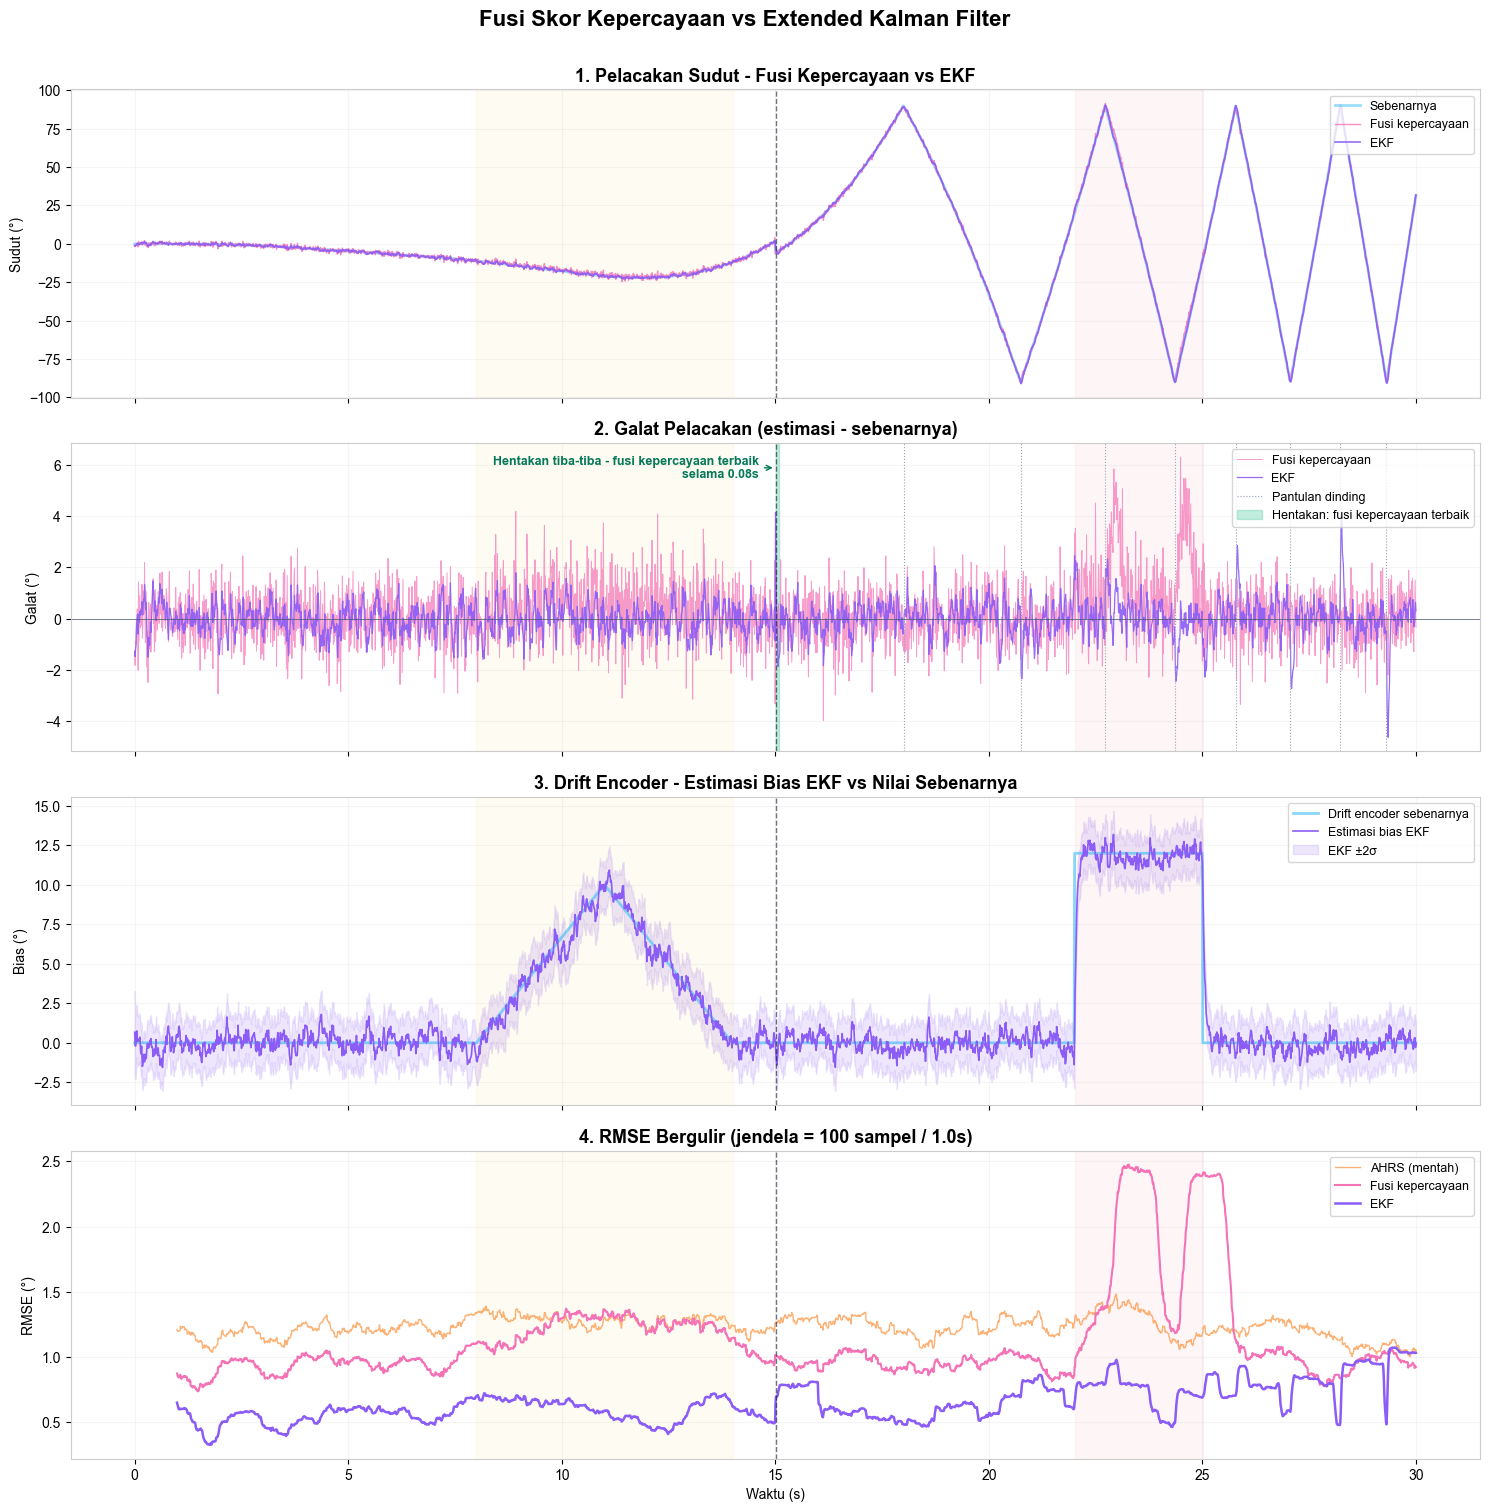

  Segment                        AHRS  Confidence      EKF   bounces
  ------------------------------------------------------------------
  Nominal (0-8 s)              1.210°      0.947°   0.566°         0
  Drift ramp (8-14 s)          1.276°      1.237°   0.608°         0
  Nominal (14-15 s)            1.263°      1.016°   0.501°         0
  Jolt (15-15.1 s)             1.281°      0.739°   1.990°         0
  Nominal (15.1-22 s)          1.243°      0.950°   0.619°         2
  12° glitch (22-25 s)         1.280°      2.134°   0.751°         2
  Recovery (25-30 s)           1.155°      0.970°   0.873°         4


In [11]:
# Wall bounces: the reflective boundary flips ω within a single step
bounce_idx = np.where(np.abs(np.diff(omega)) > 5.0)[0] + 1

fig, axes = plt.subplots(4, 1, figsize=(15, 15), sharex=True)

# -- Panel 1: Angle tracking
axes[0].plot(t, theta_true,  color='#38bdf8', lw=2.0, alpha=0.5, label='Sebenarnya')
axes[0].plot(t, theta_fused, color='#f472b6', lw=1.0, alpha=0.8, label='Fusi kepercayaan')
axes[0].plot(t, theta_ekf,   color=C_EKF,     lw=1.2, alpha=0.9, label='EKF')
mark_events(axes[0])
axes[0].set_title('1. Pelacakan Sudut - Fusi Kepercayaan vs EKF', fontsize=13, fontweight='bold')
axes[0].set_ylabel('Sudut (°)')
axes[0].legend(loc='upper right', fontsize=9); axes[0].grid(alpha=0.12)

# -- Panel 2: Tracking error
axes[1].plot(t, err_fused, color='#f472b6', lw=0.7, alpha=0.7, label='Fusi kepercayaan')
axes[1].plot(t, err_ekf,   color=C_EKF,     lw=0.9, alpha=0.9, label='EKF')
axes[1].axhline(y=0, color='#475569', ls='-', lw=0.5)
for i, b in enumerate(bounce_idx):
    axes[1].axvline(t[b], color='#94a3b8', ls=':', lw=0.8, label='Pantulan dinding' if i == 0 else None)
mark_events(axes[1])
mark_jolt_win(axes[1], label=True, note=True)
axes[1].set_title('2. Galat Pelacakan (estimasi - sebenarnya)', fontsize=13, fontweight='bold')
axes[1].set_ylabel('Galat (°)')
axes[1].legend(loc='upper right', fontsize=9); axes[1].grid(alpha=0.12)

# -- Panel 3: Drift handling
axes[2].plot(t, drift_enc, color='#38bdf8', lw=2.0, alpha=0.6, label='Drift encoder sebenarnya')
axes[2].plot(t, bias_ekf,  color=C_EKF,     lw=1.2, label='Estimasi bias EKF')
axes[2].fill_between(t, bias_ekf - 2 * ekf_sd[:, 2], bias_ekf + 2 * ekf_sd[:, 2],
                     color=C_EKF, alpha=0.15, label='EKF ±2σ')
mark_events(axes[2])
axes[2].set_title('3. Drift Encoder - Estimasi Bias EKF vs Nilai Sebenarnya', fontsize=13, fontweight='bold')
axes[2].set_ylabel('Bias (°)')
axes[2].legend(loc='upper right', fontsize=9); axes[2].grid(alpha=0.12)

# -- Panel 4: Rolling RMSE
axes[3].plot(t, roll_rmse_ahrs,  color='#fb923c', lw=1.0, alpha=0.7, label='AHRS (mentah)')
axes[3].plot(t, roll_rmse_fused, color='#f472b6', lw=1.5, label='Fusi kepercayaan')
axes[3].plot(t, roll_rmse_ekf,   color=C_EKF,     lw=1.8, label='EKF')
mark_events(axes[3])
axes[3].set_title(f'4. RMSE Bergulir (jendela = {ACCURACY_WINDOW} sampel / {ACCURACY_WINDOW*dt:.1f}s)',
                  fontsize=13, fontweight='bold')
axes[3].set_xlabel('Waktu (s)'); axes[3].set_ylabel('RMSE (°)')
axes[3].legend(loc='upper right', fontsize=9); axes[3].grid(alpha=0.12)

fig.suptitle('Fusi Skor Kepercayaan vs Extended Kalman Filter',
             fontsize=16, fontweight='bold', y=1.005)
plt.tight_layout()
plt.show()

# ── Per-segment RMSE: where does each method win? ─────────────────────────
segments = [
    ('Nominal (0-8 s)',      slice(0, 800)),
    ('Drift ramp (8-14 s)',  slice(800, 1400)),
    (f'Nominal (14-{t[JOLT_IDX]:.0f} s)', slice(1400, JOLT_IDX)),
    (f'Jolt ({t[JOLT_IDX]:.0f}-{t[jolt_seg.stop]:.1f} s)', jolt_seg),
    (f'Nominal ({t[jolt_seg.stop]:.1f}-22 s)', slice(jolt_seg.stop, 2200)),
    ('12° glitch (22-25 s)', slice(2200, 2500)),
    ('Recovery (25-30 s)',   slice(2500, N)),
]
seg_rmse = lambda e, s: np.sqrt(np.mean(e[s]**2))
print(f'  {"Segment":<26s} {"AHRS":>8s} {"Confidence":>11s} {"EKF":>8s}   {"bounces":>7s}')
print('  ' + '-' * 66)
for name, s in segments:
    n_b = np.sum((bounce_idx >= s.start) & (bounce_idx < s.stop))
    print(f'  {name:<26s} {seg_rmse(err_ahrs, s):>7.3f}° {seg_rmse(err_fused, s):>10.3f}° '
          f'{seg_rmse(err_ekf, s):>7.3f}°   {n_b:>7d}')

### 10.3 Sudden Jolt — Zoomed View

A close-up of the $8^\circ$ jolt at $t = 15$ s (0.5 s before to 1.5 s after):

1. **Angle**: both sensors jump with the antenna. The confidence fusion jumps with them, while the EKF lags behind the step
2. **Absolute error**: the green band is the **confidence-fusion-best window**, which lasts until the EKF has
   recovered from the step (its RMSE over the next 0.1 s drops below the confidence fusion's)
3. **Confidence weights**: both sensors see the same step, so the drift penalty does not fire and the weights
   stay near their nominal values

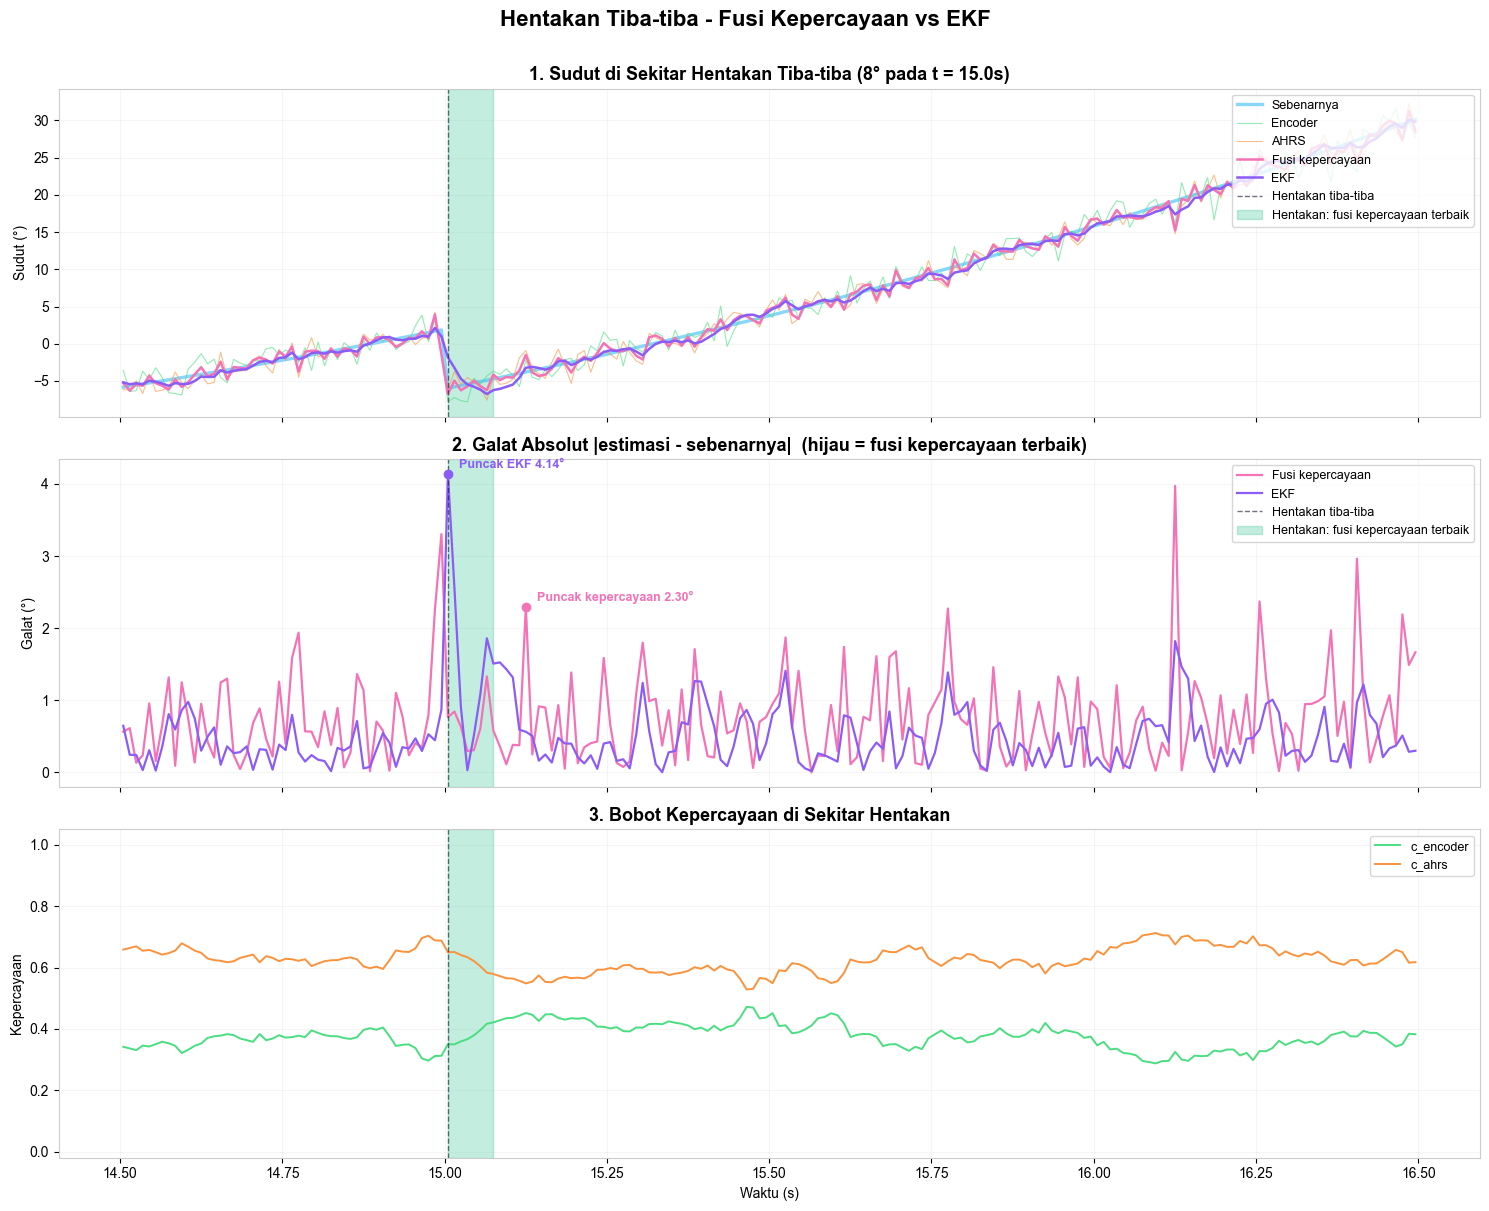

  Confidence-fusion-best window: 8 samples (0.08s) after t = 15.0s
  Signal          window RMSE  peak (1 s)
  ----------------------------------------
  Encoder              1.454°      3.257°
  AHRS                 1.281°      2.886°
  Confidence           0.739°      2.299°
  EKF                  1.990°      4.139°
  Confidence v2        0.797°      2.469°


In [12]:
# ══════════════════════════════════════════════════════════════════════════
#  SUDDEN JOLT — ZOOMED VIEW
# ══════════════════════════════════════════════════════════════════════════

zoom = slice(JOLT_IDX - 50, JOLT_IDX + 150)  # 0.5 s before to 1.5 s after
tz = t[zoom]

def mark_jolt(ax, label=False):
    ax.axvline(t[JOLT_IDX], color='#0f172a', ls='--', lw=1.0, alpha=0.6, label='Hentakan tiba-tiba' if label else None)
    mark_jolt_win(ax, label=label)

fig, axes = plt.subplots(3, 1, figsize=(15, 12), sharex=True)

# -- Panel 1: Angle
axes[0].plot(tz, theta_true[zoom],  color='#38bdf8', lw=2.4, alpha=0.6, label='Sebenarnya')
axes[0].plot(tz, theta_enc[zoom],   color='#4ade80', lw=0.8, alpha=0.6, label='Encoder')
axes[0].plot(tz, theta_ahrs[zoom],  color='#fb923c', lw=0.8, alpha=0.6, label='AHRS')
axes[0].plot(tz, theta_fused[zoom], color='#f472b6', lw=1.8, label='Fusi kepercayaan')
axes[0].plot(tz, theta_ekf[zoom],   color=C_EKF,     lw=1.8, label='EKF')
mark_jolt(axes[0], label=True)
axes[0].set_title(f'1. Sudut di Sekitar Hentakan Tiba-tiba ({JOLT_AMP:g}° pada t = {t[JOLT_IDX]:.1f}s)',
                  fontsize=13, fontweight='bold')
axes[0].set_ylabel('Sudut (°)')
axes[0].legend(loc='upper right', fontsize=9); axes[0].grid(alpha=0.12)

# -- Panel 2: Absolute error
axes[1].plot(tz, abs_err_fused[zoom], color='#f472b6', lw=1.6, label='Fusi kepercayaan')
axes[1].plot(tz, abs_err_ekf[zoom],   color=C_EKF,     lw=1.6, label='EKF')
mark_jolt(axes[1], label=True)
after = slice(JOLT_IDX, JOLT_IDX + 100)  # peaks within 1 s of the jolt
for err, color, name in ((abs_err_fused, '#f472b6', 'kepercayaan'), (abs_err_ekf, C_EKF, 'EKF')):
    i_pk = JOLT_IDX + int(np.argmax(err[after]))
    axes[1].plot(t[i_pk], err[i_pk], 'o', color=color, ms=6)
    axes[1].annotate(f'Puncak {name} {err[i_pk]:.2f}°', xy=(t[i_pk], err[i_pk]), xytext=(8, 4),
                     textcoords='offset points', fontsize=9, color=color, fontweight='bold')
axes[1].set_title('2. Galat Absolut |estimasi - sebenarnya|  (hijau = fusi kepercayaan terbaik)',
                  fontsize=13, fontweight='bold')
axes[1].set_ylabel('Galat (°)')
axes[1].legend(loc='upper right', fontsize=9); axes[1].grid(alpha=0.12)

# -- Panel 3: Confidence weights
axes[2].plot(tz, c_enc[zoom],  color='#4ade80', lw=1.4, label='c_encoder')
axes[2].plot(tz, c_ahrs[zoom], color='#fb923c', lw=1.4, label='c_ahrs')
mark_jolt(axes[2])
axes[2].set_title('3. Bobot Kepercayaan di Sekitar Hentakan', fontsize=13, fontweight='bold')
axes[2].set_xlabel('Waktu (s)'); axes[2].set_ylabel('Kepercayaan'); axes[2].set_ylim(-0.02, 1.05)
axes[2].legend(loc='upper right', fontsize=9); axes[2].grid(alpha=0.12)

fig.suptitle('Hentakan Tiba-tiba - Fusi Kepercayaan vs EKF', fontsize=16, fontweight='bold', y=1.005)
plt.tight_layout()
plt.show()

# ── Jolt response table ───────────────────────────────────────────────────
rows = [('Encoder', err_enc), ('AHRS', err_ahrs), ('Confidence', err_fused), ('EKF', err_ekf)]
if 'theta_fused_v2' in globals():  # confidence v2 from §9
    rows.append(('Confidence v2', theta_fused_v2 - theta_true))
print(f'  Confidence-fusion-best window: {JOLT_WIN} samples ({JOLT_WIN*dt:.2f}s) after t = {t[JOLT_IDX]:.1f}s')
print(f'  {"Signal":<14s} {"window RMSE":>12s} {"peak (1 s)":>11s}')
print('  ' + '-' * 40)
for name, e in rows:
    print(f'  {name:<14s} {np.sqrt(np.mean(e[jolt_seg]**2)):>11.3f}° {np.abs(e[after]).max():>10.3f}°')
